# theLook Analytics · 03 · Funnel, attribution e A/B test

theLook non contiene esperimenti, e il suo generatore decide funnel e canali con regole fisse (vedi il README). Per le domande 2 (funnel), 1 (attribution) e 5 (A/B test) questo notebook usa un secondo dataset: [E-Commerce Clickstream Simulation Dataset](https://www.kaggle.com/datasets/amith1707/e-commerce-clickstream-simulation-dataset) su Kaggle, licenza CC0. Sono 5,77 milioni di sessioni simulate su cinque marketplace, dal 2023 al 2024, con 6 esperimenti A/B.

- **Funnel:** dove si perdono le sessioni tra carrello, checkout e acquisto, e se cambia per canale, browser, dispositivo o piattaforma.
- **Attribution:** quanto vale ciascun canale secondo cinque modelli, dal last click alle catene di Markov.
- **A/B test:** controllo dell'assegnazione, potenza statistica, lettura frequentista e bayesiana, effetti per segmento e nel tempo.

Tutto gira in Google Colab: i file restano sul disco di Colab e si interrogano in SQL con **DuckDB**, senza caricarli in memoria.

**Come eseguirlo**: *Runtime → Esegui tutto*. Ci vogliono circa 10 minuti, quasi tutti per scaricare e caricare i dati.

## 1 · Download e caricamento

`kagglehub` scarica i dataset pubblici di Kaggle senza account. Se chiede le credenziali, esegui `kagglehub.login()` in una cella nuova e inserisci tu nome utente e chiave API di Kaggle.

Si carica solo il file completo (`data/full`), una riga per sessione, con le colonne che servono. Gli altri file del dataset ne sono sottoinsiemi: per esempio `clickstream_experiments` contiene le 4.264.236 sessioni con almeno un esperimento.

In [1]:
import os
import re

try:
    import kagglehub
except ImportError:
    !pip install -q kagglehub
    import kagglehub

path = kagglehub.dataset_download("amith1707/e-commerce-clickstream-simulation-dataset")
print("Cartella:", path)

100%|██████████| 3.10G/3.10G [02:29<00:00, 22.2MB/s]

Extracting files...


Cartella: /root/.cache/kagglehub/datasets/amith1707/e-commerce-clickstream-simulation-dataset/versions/1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import duckdb
except ImportError:
    !pip install -q duckdb
    import duckdb

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

ACCENTO, GRIGIO, SCURO = "#118DFF", "#C8C8C8", "#555555"
Z = stats.norm.ppf(0.975)       # livello di confidenza 95%
Z_POT = stats.norm.ppf(0.80)    # potenza 80%

con = duckdb.connect("/content/clickstream.duckdb")


def q(sql):
    return con.sql(sql).df()


def esiste(tabella):
    sql = f"SELECT COUNT(*) FROM information_schema.tables WHERE table_name = '{tabella}'"
    return con.sql(sql).fetchone()[0] > 0


def pct(x, d=1):
    return "–" if pd.isna(x) else f"{x * 100:.{d}f}%".replace(".", ",")


def num(x, d=0):
    if pd.isna(x):
        return "–"
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def wilson(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + Z**2 / n
    centro = (p + Z**2 / (2 * n)) / den
    mezzo = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n**2)) / den
    return centro - mezzo, centro + mezzo


def holm(p):
    p = np.asarray(p, float)
    m, corretti, massimo = len(p), np.empty(len(p)), 0.0
    for rango, i in enumerate(np.argsort(p)):
        massimo = max(massimo, min(1.0, (m - rango) * p[i]))
        corretti[i] = massimo
    return corretti


COLONNE = """
    session_id, user_id_hash AS user_id, session_start, platform, device_type, browser,
    traffic_source, landing_page_type, had_cart_event, checkout_started, had_purchase,
    COALESCE(session_revenue_usd, 0) AS ricavi, is_bot_suspect,
    customer_segment, user_archetype, primary_device, country,
    enrolled_experiments, enrolled_variants
"""

if not esiste("sessioni_tutte"):
    # Se il file completo è già nel database (esecuzione precedente nella stessa sessione), si parte da lì
    file_completo = os.path.join(path, "data", "full", "clickstream_full.csv")
    origine = "clickstream_full" if esiste("clickstream_full") else f"read_csv_auto('{file_completo}')"
    con.sql(f"CREATE TABLE sessioni_tutte AS SELECT {COLONNE} FROM {origine}")

print(num(con.sql("SELECT COUNT(*) FROM sessioni_tutte").fetchone()[0]), "sessioni caricate")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

5.772.828 sessioni caricate


## 2 · Il dataset e i suoi limiti

L'esplorazione (prima versione di questo notebook) ha confrontato la documentazione del dataset con i dati:

- **Periodo e copertura:** 1 gennaio 2023 – 31 dicembre 2024, circa 500.000 utenti, 5 marketplace (Amazon, eBay, Walmart, Flipkart, BestBuy).
- **Documentazione e dati non coincidono:** conversione 0,78% contro lo 0,9% dichiarato; rimbalzi 2,3% contro 3,7%; 11 paesi contro 10 (c'è anche il Messico); due segnali descritti, `fake_discount_exposure` e `post_purchase_regret_flag`, sono sempre falsi. Valgono i dati.
- **Bot:** 121.242 sessioni (2,1%) sono segnalate come sospette. Si escludono da tutte le analisi.
- **Dati sintetici:** come per theLook, i risultati mostrano il metodo. Alcuni effetti possono essere stati scritti nel generatore.

La cella seguente ripete i controlli principali e crea la tabella `sessioni` su cui lavorano tutte le analisi: senza bot e senza sessioni duplicate.

In [3]:
controllo = q("""
SELECT COUNT(*) AS righe,
       COUNT(DISTINCT session_id) AS sessioni_distinte,
       COUNT(DISTINCT user_id) AS utenti,
       MIN(session_start)::DATE AS dal,
       MAX(session_start)::DATE AS al,
       AVG(had_purchase::INTEGER) AS conversione,
       SUM(is_bot_suspect::INTEGER) AS sessioni_bot,
       AVG(CASE WHEN is_bot_suspect THEN had_purchase::INTEGER END) AS conversione_bot,
       AVG(CASE WHEN NOT is_bot_suspect THEN had_purchase::INTEGER END) AS conversione_senza_bot
FROM sessioni_tutte
""")
print(controllo.T.to_string(header=False), "\n")

duplicati = q("""
SELECT COUNT(*) AS id_ripetuti,
       COALESCE(SUM(n), 0) AS righe_coinvolte,
       COALESCE(SUM((utenti > 1)::INTEGER), 0) AS id_con_utenti_diversi
FROM (SELECT session_id, COUNT(*) AS n, COUNT(DISTINCT user_id) AS utenti
      FROM sessioni_tutte GROUP BY session_id HAVING COUNT(*) > 1)
""")
print(duplicati.T.to_string(header=False))

con.sql("""
CREATE OR REPLACE TABLE sessioni AS
SELECT * FROM sessioni_tutte
WHERE NOT is_bot_suspect
QUALIFY ROW_NUMBER() OVER (PARTITION BY session_id, user_id ORDER BY session_start) = 1
""")
print("\nSessioni analizzate, senza bot e senza duplicati:", num(con.sql("SELECT COUNT(*) FROM sessioni").fetchone()[0]))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

righe                              5772828
sessioni_distinte                  5772828
utenti                              498996
dal                    2023-01-01 00:00:00
al                     2024-12-31 00:00:00
conversione                       0.007816
sessioni_bot                      121242.0
conversione_bot                        0.0
conversione_senza_bot             0.007983 



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

id_ripetuti            0.0
righe_coinvolte        0.0
id_con_utenti_diversi  0.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Sessioni analizzate, senza bot e senza duplicati: 5.651.586


In [4]:
# Cosa dice la documentazione del dataset sugli esperimenti
readme = open(os.path.join(path, "README.md"), encoding="utf-8").read()
for sezione in re.split(r"\n(?=#{2,4} )", readme):
    titolo = sezione.strip().splitlines()[0] if sezione.strip() else ""
    if re.search(r"experiment|a/b", titolo, re.IGNORECASE):
        print(sezione.strip()[:4000], "\n")

### A/B Experiment Framework:

| Experiment                   | Description                                                                                           |
| ---------------------------- | ----------------------------------------------------------------------------------------------------- |
| **social_proof_overlay**     | Displays real-time viewer counts and recent purchase notifications on product pages                   |
| **fake_discount_detection**  | UI treatment surfacing "inflated reference price" warnings to the user                                |
| **all_time_low_badge**       | Badge shown when a product is at its 52-week minimum price                                            |
| **sale_event_urgency_timer** | Countdown timer displayed during active sale events to create urgency                                 |
| **platform_price_comparison**| Inline cross-platform price comparison widget embedded on product pages                               |
| **anchor

## 3 · Funnel (domanda 2)

Ogni sessione ha tre passaggi: aggiunta al carrello, inizio del checkout, acquisto. Prima il funnel complessivo, poi per canale, browser, dispositivo e piattaforma.

Con milioni di sessioni anche differenze minime risultano statisticamente significative, quindi il p-value dice poco. Per capire se una differenza conta si usa la **V di Cramér**, che misura la forza dell'associazione: sotto 0,1 è trascurabile.

In [5]:
f = q("""
SELECT COUNT(*) AS sessioni,
       SUM(had_cart_event::INTEGER) AS carrello,
       SUM(checkout_started::INTEGER) AS checkout,
       SUM(had_purchase::INTEGER) AS acquisto,
       SUM((checkout_started AND NOT had_cart_event)::INTEGER) AS checkout_senza_carrello,
       SUM((had_purchase AND NOT checkout_started)::INTEGER) AS acquisto_senza_checkout
FROM sessioni
""").iloc[0]
print("Coerenza dei passaggi: checkout senza carrello", num(f["checkout_senza_carrello"]),
      "· acquisti senza checkout", num(f["acquisto_senza_checkout"]), "\n")

funnel = pd.DataFrame({"fase": ["Sessioni", "Carrello", "Checkout", "Acquisto"],
                       "n": [float(f[c]) for c in ["sessioni", "carrello", "checkout", "acquisto"]]})
funnel["sul totale"] = funnel["n"] / funnel["n"].iloc[0]
funnel["sulla fase precedente"] = funnel["n"] / funnel["n"].shift(1)
funnel["persi"] = funnel["n"].shift(1) - funnel["n"]
display(pd.DataFrame({
    "fase": funnel["fase"],
    "sessioni": funnel["n"].map(num),
    "% sul totale": funnel["sul totale"].map(lambda x: pct(x, 2)),
    "% sulla fase precedente": funnel["sulla fase precedente"].map(pct),
    "persi nel passaggio": funnel["persi"].map(num),
}))

Coerenza dei passaggi: checkout senza carrello 0 · acquisti senza checkout 0 



,fase,sessioni,% sul totale,% sulla fase precedente,persi nel passaggio
0,Sessioni,5.651.586,"100,00%",–,–
1,Carrello,182.712,"3,23%","3,2%",5.468.874
2,Checkout,62.760,"1,11%","34,3%",119.952
3,Acquisto,45.119,"0,80%","71,9%",17.641


In [6]:
PASSAGGI = [("carrello", "sessioni", "Carrello su sessioni"),
            ("checkout", "carrello", "Checkout su carrello"),
            ("acquisto", "checkout", "Acquisto su checkout"),
            ("acquisto", "sessioni", "Conversione totale")]
DIMENSIONI = {"traffic_source": "Canale", "browser": "Browser",
              "device_type": "Dispositivo", "platform": "Piattaforma"}


def funnel_per(dim):
    d = q(f"""
    SELECT {dim} AS valore, COUNT(*) AS sessioni,
           SUM(had_cart_event::INTEGER) AS carrello,
           SUM(checkout_started::INTEGER) AS checkout,
           SUM(had_purchase::INTEGER) AS acquisto
    FROM sessioni GROUP BY 1 ORDER BY 2 DESC
    """)
    for numeratore, denominatore, nome in PASSAGGI:
        d[nome] = d[numeratore] / d[denominatore]
    return d


def cramer_v(successi, totali):
    successi, totali = np.asarray(successi, float), np.asarray(totali, float)
    tabella = np.vstack([successi, totali - successi])
    chi2, p, _, _ = stats.chi2_contingency(tabella, correction=False)
    return np.sqrt(chi2 / tabella.sum()), p


funnel_dim, sintesi = {}, []
for dim, etichetta in DIMENSIONI.items():
    d = funnel_per(dim)
    funnel_dim[dim] = d
    print(f"\n{etichetta}")
    display(pd.DataFrame({
        etichetta: d["valore"],
        "sessioni": d["sessioni"].map(num),
        **{nome: d[nome].map(lambda x: pct(x, 2)) for _, _, nome in PASSAGGI},
    }))
    for numeratore, denominatore, nome in PASSAGGI:
        v, p = cramer_v(d[numeratore], d[denominatore])
        tassi = d[nome]
        sintesi.append({"dimensione": etichetta, "passaggio": nome,
                        "V di Cramér": round(v, 4), "p": f"{p:.1e}",
                        "più basso": f"{d['valore'][tassi.idxmin()]} {pct(tassi.min(), 2)}",
                        "più alto": f"{d['valore'][tassi.idxmax()]} {pct(tassi.max(), 2)}",
                        "alto / basso": round(tassi.max() / tassi.min(), 2)})

print("\nQuanto contano le differenze (V di Cramér: sotto 0,1 trascurabile)")
sintesi_funnel = pd.DataFrame(sintesi)
display(sintesi_funnel)


Canale


,Canale,sessioni,Carrello su sessioni,Checkout su carrello,Acquisto su checkout,Conversione totale
0,organic_search,1.754.966,"3,23%","34,28%","71,88%","0,79%"
1,direct,1.242.227,"3,25%","34,58%","71,61%","0,80%"
2,paid_search,1.011.409,"3,22%","34,53%","72,08%","0,80%"
3,social,794.040,"3,22%","34,14%","72,44%","0,80%"
4,email,452.305,"3,23%","34,51%","71,50%","0,80%"
5,referral,282.635,"3,27%","33,05%","72,07%","0,78%"
6,affiliate,114.004,"3,33%","35,34%","70,99%","0,84%"



Browser


,Browser,sessioni,Carrello su sessioni,Checkout su carrello,Acquisto su checkout,Conversione totale
0,chrome,3.677.173,"3,23%","34,34%","71,77%","0,80%"
1,safari,1.125.185,"3,22%","34,25%","71,95%","0,79%"
2,firefox,396.089,"3,24%","34,24%","72,91%","0,81%"
3,edge,282.984,"3,25%","34,38%","71,26%","0,80%"
4,other,170.155,"3,27%","35,37%","72,70%","0,84%"



Dispositivo


,Dispositivo,sessioni,Carrello su sessioni,Checkout su carrello,Acquisto su checkout,Conversione totale
0,mobile,2.714.121,"3,24%","34,42%","71,63%","0,80%"
1,desktop,2.370.137,"3,24%","34,35%","72,21%","0,80%"
2,tablet,452.757,"3,20%","34,06%","71,61%","0,78%"
3,smart_tv,114.571,"3,22%","33,82%","72,55%","0,79%"



Piattaforma


,Piattaforma,sessioni,Carrello su sessioni,Checkout su carrello,Acquisto su checkout,Conversione totale
0,Amazon,1.813.001,"3,23%","37,93%","71,84%","0,88%"
1,eBay,1.131.726,"3,22%","37,52%","71,68%","0,87%"
2,Walmart,1.125.395,"3,22%","38,39%","72,38%","0,90%"
3,Flipkart,904.817,"3,27%","15,89%","71,06%","0,37%"
4,BestBuy,676.647,"3,22%","37,76%","72,04%","0,88%"



Quanto contano le differenze (V di Cramér: sotto 0,1 trascurabile)


,dimensione,passaggio,V di Cramér,p,più basso,più alto,alto / basso
0,Canale,Carrello su sessioni,0.0011,3.4e-01,"paid_search 3,22%","affiliate 3,33%",1.04
1,Canale,Checkout su carrello,0.0077,9.5e-02,"referral 33,05%","affiliate 35,34%",1.07
2,Canale,Acquisto su checkout,0.0069,8.1e-01,"affiliate 70,99%","social 72,44%",1.02
3,Canale,Conversione totale,0.0009,6.5e-01,"referral 0,78%","affiliate 0,84%",1.07
4,Browser,Carrello su sessioni,0.0006,6.8e-01,"safari 3,22%","other 3,27%",1.02
5,Browser,Checkout su carrello,0.0039,5.9e-01,"firefox 34,24%","other 35,37%",1.03
6,Browser,Acquisto su checkout,0.0078,4.3e-01,"edge 71,26%","firefox 72,91%",1.02
7,Browser,Conversione totale,0.0010,2.5e-01,"safari 0,79%","other 0,84%",1.06
8,Dispositivo,Carrello su sessioni,0.0007,4.9e-01,"tablet 3,20%","desktop 3,24%",1.01
9,Dispositivo,Checkout su carrello,0.0025,7.7e-01,"smart_tv 33,82%","mobile 34,42%",1.02


### Dove si perde di più

L'unica differenza che conta è tra piattaforme, nel passaggio dal carrello al checkout. Le celle seguenti la mostrano, verificano se dipende da un dispositivo, un canale, un paese o un periodo, e stimano quanto vale.

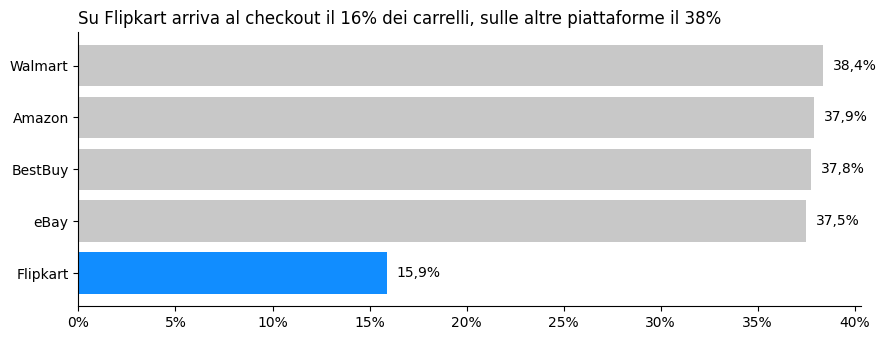

In [7]:
piattaforme = funnel_dim["platform"]
PEGGIORE = piattaforme.loc[piattaforme["Checkout su carrello"].idxmin(), "valore"]
altre = piattaforme[piattaforme["valore"] != PEGGIORE]
tasso_peggiore = piattaforme.loc[piattaforme["valore"] == PEGGIORE, "Checkout su carrello"].iloc[0]
tasso_altre = altre["checkout"].sum() / altre["carrello"].sum()

d = piattaforme.sort_values("Checkout su carrello")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(d["valore"], d["Checkout su carrello"] * 100,
        color=[ACCENTO if v == PEGGIORE else GRIGIO for v in d["valore"]])
for y, v in enumerate(d["Checkout su carrello"]):
    ax.text(v * 100 + 0.5, y, pct(v), va="center", fontsize=10)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Su {PEGGIORE} arriva al checkout il {pct(tasso_peggiore, 0)} dei carrelli, "
             f"sulle altre piattaforme il {pct(tasso_altre, 0)}", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

In [8]:
# Il calo dipende da un dispositivo, un canale, un paese o un periodo?
SCOMPOSIZIONI = {"device_type": "Dispositivo", "traffic_source": "Canale", "country": "Paese",
                 "date_trunc('quarter', session_start)::DATE": "Trimestre"}
for espressione, etichetta in SCOMPOSIZIONI.items():
    d = q(f"""
    SELECT {espressione} AS valore,
           SUM(CASE WHEN platform = '{PEGGIORE}' THEN 1 ELSE 0 END) AS carrelli,
           SUM(CASE WHEN platform = '{PEGGIORE}' THEN checkout_started::INTEGER END)
             / SUM(CASE WHEN platform = '{PEGGIORE}' THEN 1 END) AS tasso_peggiore,
           SUM(CASE WHEN platform <> '{PEGGIORE}' THEN checkout_started::INTEGER END)
             / SUM(CASE WHEN platform <> '{PEGGIORE}' THEN 1 END) AS tasso_altre
    FROM sessioni WHERE had_cart_event
    GROUP BY 1 ORDER BY 1
    """)
    print(f"\nCheckout su carrello per {etichetta.lower()}")
    display(pd.DataFrame({
        etichetta: d["valore"].astype(str),
        f"carrelli su {PEGGIORE}": d["carrelli"].map(num),
        PEGGIORE: d["tasso_peggiore"].map(pct),
        "altre piattaforme": d["tasso_altre"].map(pct),
        "rapporto": (d["tasso_peggiore"] / d["tasso_altre"]).map(lambda x: num(x, 2)),
    }))


Checkout su carrello per dispositivo


,Dispositivo,carrelli su Flipkart,Flipkart,altre piattaforme,rapporto
0,desktop,12.545,"16,3%","37,9%","0,43"
1,mobile,14.070,"15,6%","38,0%","0,41"
2,smart_tv,624,"15,5%","37,5%","0,41"
3,tablet,2.361,"15,7%","37,7%","0,42"



Checkout su carrello per canale


,Canale,carrelli su Flipkart,Flipkart,altre piattaforme,rapporto
0,affiliate,579,"15,7%","38,9%","0,40"
1,direct,6.520,"15,7%","38,2%","0,41"
2,email,2.412,"16,5%","38,1%","0,43"
3,organic_search,9.147,"15,9%","37,8%","0,42"
4,paid_search,5.164,"16,0%","38,0%","0,42"
5,referral,1.597,"16,5%","36,5%","0,45"
6,social,4.181,"15,5%","37,8%","0,41"



Checkout su carrello per paese


,Paese,carrelli su Flipkart,Flipkart,altre piattaforme,rapporto
0,AU,2.060,"16,3%","37,3%","0,44"
1,BR,885,"16,7%","38,6%","0,43"
2,CA,1.740,"14,0%","38,4%","0,36"
3,DE,2.317,"16,1%","38,1%","0,42"
4,FR,1.481,"15,5%","38,4%","0,40"
5,IN,5.350,"16,6%","38,0%","0,44"
6,JP,589,"14,3%","37,5%","0,38"
7,MX,624,"17,1%","37,6%","0,46"
8,SG,639,"13,9%","38,6%","0,36"
9,UK,3.628,"15,5%","38,1%","0,41"



Checkout su carrello per trimestre


,Trimestre,carrelli su Flipkart,Flipkart,altre piattaforme,rapporto
0,2023-01-01,3.292,"16,0%","37,8%","0,42"
1,2023-04-01,3.297,"16,2%","37,5%","0,43"
2,2023-07-01,3.432,"16,0%","38,4%","0,42"
3,2023-10-01,5.060,"16,2%","37,7%","0,43"
4,2024-01-01,3.263,"16,1%","38,3%","0,42"
5,2024-04-01,3.274,"15,2%","37,8%","0,40"
6,2024-07-01,3.177,"15,6%","37,7%","0,41"
7,2024-10-01,4.805,"15,7%","38,1%","0,41"


In [9]:
# Quanto vale il problema: acquisti e ricavi in più se il passaggio al checkout fosse come sulle altre piattaforme
valore = q(f"""
SELECT SUM(had_cart_event::INTEGER) AS carrelli,
       AVG(CASE WHEN checkout_started THEN had_purchase::INTEGER END) AS acquisto_su_checkout,
       AVG(CASE WHEN had_purchase THEN ricavi END) AS ricavo_medio_acquisto,
       SUM(ricavi) AS ricavi
FROM sessioni WHERE platform = '{PEGGIORE}'
""").iloc[0]
checkout_in_piu = valore["carrelli"] * (tasso_altre - tasso_peggiore)
acquisti_in_piu = checkout_in_piu * valore["acquisto_su_checkout"]
ricavi_in_piu = acquisti_in_piu * valore["ricavo_medio_acquisto"]
print(f"{PEGGIORE}, 2023–2024: {num(valore['carrelli'])} carrelli, ricavi ${num(valore['ricavi'])}")
print(f"Con il passaggio al checkout delle altre piattaforme ({pct(tasso_altre)} invece di {pct(tasso_peggiore)}):")
print(f"  +{num(checkout_in_piu)} checkout, +{num(acquisti_in_piu)} acquisti, "
      f"+${num(ricavi_in_piu)} di ricavi in due anni ({pct(ricavi_in_piu / valore['ricavi'], 0)} in più)")

Flipkart, 2023–2024: 29.600 carrelli, ricavi $612.778
Con il passaggio al checkout delle altre piattaforme (37,9% invece di 15,9%):
  +6.521 checkout, +4.634 acquisti, +$849.618 di ricavi in due anni (139% in più)


## 4 · Attribution (domanda 1)

Prima di scegliere un modello si controlla se i dati contengono un segnale da attribuire:

1. **Il canale cambia la probabilità di acquisto?** Se tutte le sessioni convertono allo stesso modo, qualunque canale si premi, il merito finisce in proporzione al traffico.
2. **Il canale di una sessione dipende da quello della precedente?** Se i percorsi sono casuali, i modelli multi-touch non hanno struttura su cui lavorare (è quello che succede in theLook).

Poi si costruiscono i **percorsi**: per ogni utente, le sessioni dalla prima (o dal giorno dopo l'acquisto precedente) fino all'acquisto. Su questi percorsi si confrontano cinque modelli: last click, first click, lineare, a U (40% alla prima sessione, 40% all'ultima, 20% alle altre) e **catene di Markov**, che misurano quanto calano le conversioni se si toglie un canale dai percorsi (*removal effect*).

In [10]:
# 1. Conversione per canale, con intervallo di confidenza
conv = funnel_dim["traffic_source"]
basso, alto = wilson(conv["acquisto"], conv["sessioni"])
display(pd.DataFrame({"canale": conv["valore"], "sessioni": conv["sessioni"].map(num),
                      "conversione": conv["Conversione totale"].map(lambda x: pct(x, 2)),
                      "IC 95%": [f"{pct(b, 2)} – {pct(a, 2)}" for b, a in zip(basso, alto)]}))

# 2. Canale di una sessione rispetto a quello della sessione precedente dello stesso utente
coppie = q("""
WITH s AS (
  SELECT traffic_source AS canale,
         LAG(traffic_source) OVER (PARTITION BY user_id ORDER BY session_start, session_id) AS precedente
  FROM sessioni
)
SELECT precedente, canale, COUNT(*) AS n
FROM s WHERE precedente IS NOT NULL
GROUP BY 1, 2
""")
tabella = coppie.pivot(index="precedente", columns="canale", values="n").fillna(0)
chi2, p, _, _ = stats.chi2_contingency(tabella.values)
v = np.sqrt(chi2 / (tabella.values.sum() * (min(tabella.shape) - 1)))
print(f"\nCanale della sessione e canale della precedente: p = {p:.2g}, V di Cramér = {v:.3f}")
print("Canale della sessione successiva, per canale della precedente (% di riga):")
display((tabella.div(tabella.sum(axis=1), axis=0) * 100).round(1))

,canale,sessioni,conversione,IC 95%
0,organic_search,1.754.966,"0,79%","0,78% – 0,81%"
1,direct,1.242.227,"0,80%","0,79% – 0,82%"
2,paid_search,1.011.409,"0,80%","0,78% – 0,82%"
3,social,794.040,"0,80%","0,78% – 0,82%"
4,email,452.305,"0,80%","0,77% – 0,82%"
5,referral,282.635,"0,78%","0,75% – 0,81%"
6,affiliate,114.004,"0,84%","0,78% – 0,89%"


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Canale della sessione e canale della precedente: p = 0, V di Cramér = 1.000
Canale della sessione successiva, per canale della precedente (% di riga):


canale,affiliate,direct,email,organic_search,paid_search,referral,social
precedente,,,,,,,
affiliate,100.0,0.0,0.0,0.0,0.0,0.0,0.0
direct,0.0,100.0,0.0,0.0,0.0,0.0,0.0
email,0.0,0.0,100.0,0.0,0.0,0.0,0.0
organic_search,0.0,0.0,0.0,100.0,0.0,0.0,0.0
paid_search,0.0,0.0,0.0,0.0,100.0,0.0,0.0
referral,0.0,0.0,0.0,0.0,0.0,100.0,0.0
social,0.0,0.0,0.0,0.0,0.0,0.0,100.0


In [11]:
con.sql("""
CREATE OR REPLACE TABLE percorsi AS
WITH s AS (
  SELECT user_id, session_id, session_start, traffic_source AS canale, had_purchase,
         -- numero di acquisti precedenti: un nuovo percorso inizia dopo ogni acquisto
         COALESCE(SUM(had_purchase::INTEGER) OVER (
           PARTITION BY user_id ORDER BY session_start, session_id
           ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS percorso
  FROM sessioni
)
SELECT *,
       ROW_NUMBER() OVER (PARTITION BY user_id, percorso ORDER BY session_start, session_id) AS passo,
       COUNT(*) OVER (PARTITION BY user_id, percorso) AS lunghezza,
       MAX(had_purchase::INTEGER) OVER (PARTITION BY user_id, percorso) AS convertito
FROM s
""")

riepilogo = q("""
SELECT COUNT(*) AS percorsi,
       SUM(convertito) AS percorsi_con_acquisto,
       AVG(CASE WHEN convertito = 1 THEN lunghezza END) AS sessioni_medie_fino_all_acquisto,
       AVG(CASE WHEN convertito = 1 THEN (lunghezza = 1)::INTEGER END) AS quota_acquisti_alla_prima_sessione,
       AVG(CASE WHEN convertito = 1 THEN (canali = 1)::INTEGER END) AS quota_percorsi_con_un_solo_canale
FROM (SELECT user_id, percorso, ANY_VALUE(lunghezza) AS lunghezza, ANY_VALUE(convertito) AS convertito,
             COUNT(DISTINCT canale) AS canali
      FROM percorsi GROUP BY user_id, percorso)
""")
print(riepilogo.T.to_string(header=False))

regole = q("""
SELECT canale,
       SUM(CASE WHEN passo = lunghezza THEN 1 ELSE 0 END) AS "Last click",
       SUM(CASE WHEN passo = 1 THEN 1 ELSE 0 END) AS "First click",
       SUM(1 / lunghezza) AS "Lineare",
       SUM(CASE WHEN lunghezza = 1 THEN 1.0::DOUBLE
                WHEN lunghezza = 2 THEN 0.5::DOUBLE
                WHEN passo = 1 OR passo = lunghezza THEN 0.4::DOUBLE
                ELSE 0.2::DOUBLE / (lunghezza - 2) END) AS "A U"
FROM percorsi
WHERE convertito = 1
GROUP BY canale
""")
traffico = q("SELECT traffic_source AS canale, COUNT(*) AS sessioni FROM sessioni GROUP BY 1")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

percorsi                            539467.000000
percorsi_con_acquisto                45119.000000
sessioni_medie_fino_all_acquisto         6.368426
quota_acquisti_alla_prima_sessione       0.098207
quota_percorsi_con_un_solo_canale        1.000000


In [12]:
# Catene di Markov: transizioni tra canali dentro ogni percorso, dall'inizio fino ad acquisto o abbandono
transizioni = q("""
WITH t AS (
  SELECT COALESCE(LAG(canale) OVER (PARTITION BY user_id, percorso ORDER BY passo), 'start') AS da,
         canale AS a
  FROM percorsi
)
SELECT da, a, COUNT(*) AS n FROM t GROUP BY 1, 2
UNION ALL
SELECT canale AS da, CASE WHEN convertito = 1 THEN 'conv' ELSE 'null' END AS a, COUNT(*) AS n
FROM percorsi WHERE passo = lunghezza GROUP BY 1, 2
""")


def prob_conversione(transizioni, rimosso=None):
    t = transizioni.copy()
    if rimosso is not None:
        # Senza il canale, chi ci sarebbe passato abbandona il percorso
        t = t[t["da"] != rimosso].copy()
        t.loc[t["a"] == rimosso, "a"] = "null"
    stati = sorted((set(t["da"]) | set(t["a"])) - {"conv", "null"})
    indice = {s: i for i, s in enumerate(stati)}
    Q, R = np.zeros((len(stati), len(stati))), np.zeros((len(stati), 2))
    for da, a, n in t.groupby(["da", "a"], as_index=False)["n"].sum().itertuples(index=False):
        if a == "conv":
            R[indice[da], 0] += n
        elif a == "null":
            R[indice[da], 1] += n
        else:
            Q[indice[da], indice[a]] += n
    totali = Q.sum(axis=1) + R.sum(axis=1)
    totali[totali == 0] = 1
    Q, R = Q / totali[:, None], R / totali[:, None]
    assorbimento = np.linalg.solve(np.eye(len(stati)) - Q, R)
    return assorbimento[indice["start"], 0]


p_base = prob_conversione(transizioni)
canali = sorted(traffico["canale"])
removal = {c: 1 - prob_conversione(transizioni, c) / p_base for c in canali}
print(f"Probabilità di acquisto di un percorso: {pct(p_base, 2)}")
print("Removal effect (calo delle conversioni senza il canale):",
      ", ".join(f"{c} {pct(r)}" for c, r in sorted(removal.items(), key=lambda x: -x[1])), "\n")

conversioni = regole["Last click"].sum()
regole["Markov"] = regole["canale"].map(lambda c: removal[c] / sum(removal.values()) * conversioni)

MODELLI = ["Last click", "First click", "Lineare", "A U", "Markov"]
attribution = traffico.merge(regole, on="canale")
attribution["Quota di sessioni"] = attribution["sessioni"] / attribution["sessioni"].sum()
for m in MODELLI:
    attribution[m] = attribution[m] / attribution[m].sum()
attribution = attribution.sort_values("Last click", ascending=False).set_index("canale")

print("Quota di conversioni attribuita a ogni canale")
display(attribution[["Quota di sessioni"] + MODELLI].apply(lambda col: col.map(pct)))

scarti = attribution[MODELLI].sub(attribution["Quota di sessioni"], axis=0)
print(f"Scarto massimo tra un modello e la quota di sessioni: {pct(scarti.abs().max().max())}")
print(f"Scarto massimo tra Markov e last click: {pct((attribution['Markov'] - attribution['Last click']).abs().max())}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Probabilità di acquisto di un percorso: 8,36%
Removal effect (calo delle conversioni senza il canale): organic_search 30,9%, direct 22,1%, paid_search 17,9%, social 14,0%, email 8,0%, referral 4,9%, affiliate 2,1% 

Quota di conversioni attribuita a ogni canale


,Quota di sessioni,Last click,First click,Lineare,A U,Markov
canale,,,,,,
organic_search,"31,1%","30,9%","30,9%","30,9%","30,9%","30,9%"
direct,"22,0%","22,1%","22,1%","22,1%","22,1%","22,1%"
paid_search,"17,9%","17,9%","17,9%","17,9%","17,9%","17,9%"
social,"14,0%","14,0%","14,0%","14,0%","14,0%","14,0%"
email,"8,0%","8,0%","8,0%","8,0%","8,0%","8,0%"
referral,"5,0%","4,9%","4,9%","4,9%","4,9%","4,9%"
affiliate,"2,0%","2,1%","2,1%","2,1%","2,1%","2,1%"


Scarto massimo tra un modello e la quota di sessioni: 0,2%
Scarto massimo tra Markov e last click: 0,0%


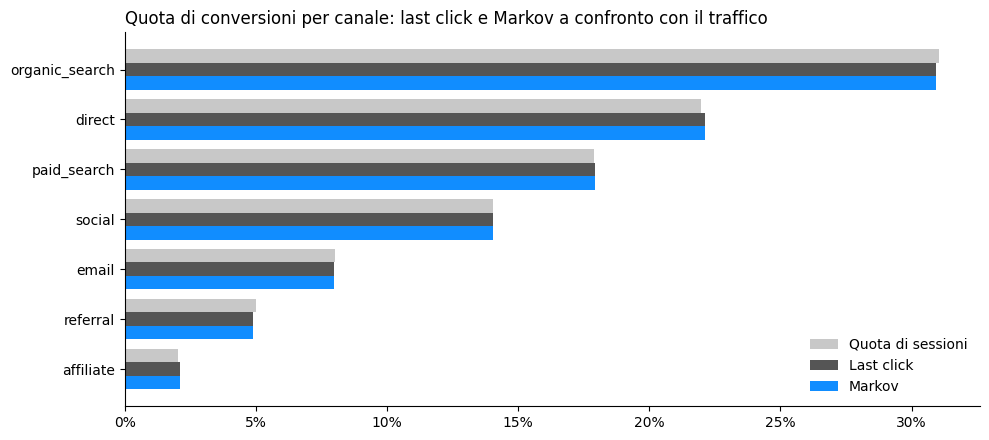

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(attribution))
altezza = 0.27
ax.barh(y - altezza, attribution["Quota di sessioni"] * 100, altezza, color=GRIGIO, label="Quota di sessioni")
ax.barh(y, attribution["Last click"] * 100, altezza, color=SCURO, label="Last click")
ax.barh(y + altezza, attribution["Markov"] * 100, altezza, color=ACCENTO, label="Markov")
ax.set_yticks(y, attribution.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Quota di conversioni per canale: last click e Markov a confronto con il traffico", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

## 5 · A/B test (domanda 5)

Ogni sessione può partecipare a più esperimenti: le colonne `enrolled_experiments` e `enrolled_variants` contengono due liste allineate, separate da `|`. Si trasformano in una riga per sessione ed esperimento.

Prima dei risultati si controlla il disegno:

- **Unità di assegnazione:** se ogni utente resta nella stessa variante per tutte le sue sessioni, l'unità di analisi è l'utente, non la sessione. Contare le sessioni di uno stesso utente come osservazioni indipendenti renderebbe gli intervalli di confidenza troppo stretti.
- **Sample ratio mismatch (SRM):** se le varianti hanno numerosità diverse da quelle previste, l'assegnazione ha un problema e i risultati non sono affidabili. Si verifica sugli esperimenti a due varianti, che dovrebbero essere divisi a metà. Per quelli a quattro varianti la ripartizione prevista non è documentata.
- **Bilanciamento:** se l'assegnazione è casuale, i gruppi hanno le stesse caratteristiche precedenti al test (archetipo, dispositivo, canale, paese). Una V di Cramér vicina a zero lo conferma, anche dove l'SRM non si può verificare.

In [14]:
lunghezze_diverse = con.sql("""
SELECT COUNT(*) FROM sessioni
WHERE enrolled_experiments IS NOT NULL
  AND len(string_split(enrolled_experiments, '|')) <> len(string_split(enrolled_variants, '|'))
""").fetchone()[0]
print("Sessioni con liste di esperimenti e varianti di lunghezza diversa:", num(lunghezze_diverse), "\n")

con.sql("""
CREATE OR REPLACE TABLE assegnazioni AS
SELECT session_id, user_id, session_start, had_purchase, had_cart_event, checkout_started, ricavi,
       customer_segment, user_archetype, primary_device, device_type, traffic_source, country,
       UNNEST(esperimenti) AS esperimento,
       UNNEST(varianti) AS variante
FROM (
  SELECT *,
         string_split(enrolled_experiments, '|') AS esperimenti,
         string_split(enrolled_variants, '|') AS varianti
  FROM sessioni
  WHERE enrolled_experiments IS NOT NULL
)
""")

panoramica = q("""
SELECT esperimento, variante, COUNT(*) AS sessioni, COUNT(DISTINCT user_id) AS utenti,
       MIN(session_start)::DATE AS dal, MAX(session_start)::DATE AS al
FROM assegnazioni GROUP BY 1, 2 ORDER BY 1, 2
""")
display(panoramica)

coerenza = q("""
SELECT esperimento, COUNT(*) AS utenti,
       AVG((varianti > 1)::INTEGER) AS quota_utenti_in_piu_varianti
FROM (SELECT esperimento, user_id, COUNT(DISTINCT variante) AS varianti
      FROM assegnazioni GROUP BY 1, 2)
GROUP BY 1 ORDER BY 1
""")
display(coerenza)

UNITA = "user_id" if coerenza["quota_utenti_in_piu_varianti"].max() < 0.01 else "session_id"
DISPOSITIVO = "primary_device" if UNITA == "user_id" else "device_type"
print("Unità di analisi:", "l'utente" if UNITA == "user_id" else "la sessione")

Sessioni con liste di esperimenti e varianti di lunghezza diversa: 0 



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,esperimento,variante,sessioni,utenti,dal,al
0,all_time_low_badge,control,565375,49870,2023-01-01,2024-12-31
1,all_time_low_badge,treatment,566366,49990,2023-01-01,2024-12-31
2,anchor_price_display,control,560928,49565,2023-01-01,2024-12-31
3,anchor_price_display,treatment,566413,49943,2023-01-01,2024-12-31
4,fake_discount_detection,control,561466,49516,2023-01-01,2024-12-31
5,fake_discount_detection,treatment,567957,50207,2023-01-01,2024-12-31
6,platform_price_comparison,control,537555,47445,2023-01-01,2024-12-31
7,platform_price_comparison,treatment,475139,41914,2023-01-01,2024-12-31
8,platform_price_comparison,treatment_full,60170,5330,2023-01-01,2024-12-31
9,platform_price_comparison,treatment_low,57979,5153,2023-01-01,2024-12-31


,esperimento,utenti,quota_utenti_in_piu_varianti
0,all_time_low_badge,99860,0.0
1,anchor_price_display,99508,0.0
2,fake_discount_detection,99723,0.0
3,platform_price_comparison,99842,0.0
4,sale_event_urgency_timer,99872,0.0
5,social_proof_overlay,100003,0.0


Unità di analisi: l'utente


In [15]:
# Una riga per esperimento e unità: conversione = almeno un acquisto nelle sessioni dell'esperimento
con.sql(f"""
CREATE OR REPLACE TABLE unita_test AS
SELECT esperimento, {UNITA} AS unita, MIN(variante) AS variante,
       MAX(had_purchase::INTEGER) AS conversione,
       MAX(had_cart_event::INTEGER) AS carrello,
       MAX(checkout_started::INTEGER) AS checkout,
       SUM(ricavi) AS ricavi,
       MIN(session_start) AS primo_ingresso,
       ANY_VALUE(customer_segment) AS segmento_cliente,
       ANY_VALUE(user_archetype) AS archetipo,
       ANY_VALUE({DISPOSITIVO}) AS dispositivo,
       ANY_VALUE(traffic_source) AS canale,
       ANY_VALUE(country) AS paese
FROM assegnazioni
GROUP BY esperimento, {UNITA}
HAVING COUNT(DISTINCT variante) = 1
""")

ris = q("""
SELECT esperimento, variante, COUNT(*) AS n, SUM(conversione) AS conversioni,
       AVG(ricavi) AS ricavi_medi, STDDEV_SAMP(ricavi) AS ricavi_sd,
       MIN(primo_ingresso)::DATE AS dal, MAX(primo_ingresso)::DATE AS al
FROM unita_test GROUP BY 1, 2 ORDER BY 1, 2
""")
ris["tasso"] = ris["conversioni"] / ris["n"]


def controllo_di(varianti):
    varianti = list(varianti)
    return "control" if "control" in varianti else sorted(varianti)[0]


srm = []
for esperimento, g in ris.groupby("esperimento"):
    riga = {"esperimento": esperimento, "varianti": " / ".join(g["variante"]),
            "unità": " / ".join(num(x) for x in g["n"]),
            "quote": " / ".join(pct(x, 0) for x in g["n"] / g["n"].sum())}
    if len(g) == 2:
        _, p = stats.chisquare(g["n"])
        riga["p SRM (50/50)"] = f"{p:.3g}"
        riga["esito"] = "OK" if p >= 0.001 else "Squilibrio: controllare l'assegnazione"
    else:
        riga["p SRM (50/50)"] = "–"
        riga["esito"] = "Ripartizione prevista non documentata: vedi bilanciamento"
    srm.append(riga)
display(pd.DataFrame(srm))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,esperimento,varianti,unità,quote,p SRM (50/50),esito
0,all_time_low_badge,control / treatment,49.870 / 49.990,50% / 50%,0.704,OK
1,anchor_price_display,control / treatment,49.565 / 49.943,50% / 50%,0.231,OK
2,fake_discount_detection,control / treatment,49.516 / 50.207,50% / 50%,0.0287,OK
3,platform_price_comparison,control / treatment / treatment_full / treatme...,47.445 / 41.914 / 5.330 / 5.153,48% / 42% / 5% / 5%,–,Ripartizione prevista non documentata: vedi bi...
4,sale_event_urgency_timer,control / treatment / treatment_full / treatme...,49.320 / 47.945 / 1.344 / 1.263,49% / 48% / 1% / 1%,–,Ripartizione prevista non documentata: vedi bi...
5,social_proof_overlay,control / treatment / treatment_full / treatme...,36.968 / 9.994 / 26.683 / 26.358,37% / 10% / 27% / 26%,–,Ripartizione prevista non documentata: vedi bi...


In [16]:
# Bilanciamento: le varianti hanno le stesse caratteristiche precedenti al test?
COVARIATE = {"archetipo": "Archetipo", "dispositivo": "Dispositivo", "canale": "Canale", "paese": "Paese"}
bilanciamento = []
for esperimento in ris["esperimento"].unique():
    riga = {"esperimento": esperimento}
    for col, etichetta in COVARIATE.items():
        d = q(f"""
        SELECT variante, {col} AS livello, COUNT(*) AS n
        FROM unita_test WHERE esperimento = '{esperimento}'
        GROUP BY 1, 2
        """)
        tabella = d.pivot(index="variante", columns="livello", values="n").fillna(0)
        chi2, p, _, _ = stats.chi2_contingency(tabella.values)
        v = np.sqrt(chi2 / (tabella.values.sum() * (min(tabella.shape) - 1)))
        riga[etichetta] = f"V {v:.3f} · p {p:.2g}"
    bilanciamento.append(riga)
print("Associazione tra variante e caratteristiche dell'utente (V di Cramér vicina a 0 = gruppi simili)")
display(pd.DataFrame(bilanciamento))

Associazione tra variante e caratteristiche dell'utente (V di Cramér vicina a 0 = gruppi simili)


,esperimento,Archetipo,Dispositivo,Canale,Paese
0,all_time_low_badge,V 0.003 · p 0.98,V 0.006 · p 0.31,V 0.008 · p 0.38,V 0.007 · p 0.92
1,anchor_price_display,V 0.005 · p 0.87,V 0.005 · p 0.48,V 0.002 · p 1,V 0.014 · p 0.041
2,fake_discount_detection,V 0.012 · p 0.03,V 0.003 · p 0.81,V 0.011 · p 0.078,V 0.008 · p 0.81
3,platform_price_comparison,V 0.007 · p 0.74,V 0.007 · p 0.12,V 0.009 · p 0.13,V 0.010 · p 0.34
4,sale_event_urgency_timer,V 0.010 · p 0.048,V 0.005 · p 0.67,V 0.009 · p 0.17,V 0.010 · p 0.4
5,social_proof_overlay,V 0.008 · p 0.28,V 0.003 · p 0.99,V 0.009 · p 0.088,V 0.008 · p 0.97


### Potenza statistica

Per ogni esperimento: il più piccolo effetto che il test poteva rilevare con potenza dell'80% e confidenza del 95% (*minimum detectable effect*, MDE), e quante unità per gruppo servirebbero per rilevare un aumento del 5% della conversione, o per confermare il lift osservato quando è positivo. Un risultato non significativo con una MDE grande non vuol dire "nessun effetto": vuol dire che il test era troppo piccolo per vederlo.

La durata in giorni qui non serve: quasi tutti gli utenti entrano negli esperimenti nelle prime settimane, perché sono già clienti attivi. Per avere più unità bisogna coinvolgere più utenti, non aspettare di più.

In [17]:
confronti = []
for esperimento, g in ris.groupby("esperimento"):
    g = g.set_index("variante")
    base = controllo_di(g.index)
    c = g.loc[base]
    for variante in g.index.drop(base):
        t = g.loc[variante]
        pc, pt = c["tasso"], t["tasso"]
        se = np.sqrt(pc * (1 - pc) / c["n"] + pt * (1 - pt) / t["n"])
        pool = (c["conversioni"] + t["conversioni"]) / (c["n"] + t["n"])
        z = (pt - pc) / np.sqrt(pool * (1 - pool) * (1 / c["n"] + 1 / t["n"]))
        welch = stats.ttest_ind_from_stats(t["ricavi_medi"], t["ricavi_sd"], t["n"],
                                           c["ricavi_medi"], c["ricavi_sd"], c["n"], equal_var=False)
        confronti.append({
            "esperimento": esperimento, "variante": variante, "controllo": base,
            "n_controllo": c["n"], "n_variante": t["n"],
            "conv_controllo": c["conversioni"], "conv_variante": t["conversioni"],
            "tasso_controllo": pc, "tasso_variante": pt,
            "diff": pt - pc, "diff_basso": pt - pc - Z * se, "diff_alto": pt - pc + Z * se,
            "p": 2 * stats.norm.sf(abs(z)),
            "mde": (Z + Z_POT) * np.sqrt(pc * (1 - pc) * (1 / c["n"] + 1 / t["n"])),
            "ricavi_controllo": c["ricavi_medi"], "ricavi_variante": t["ricavi_medi"], "p_ricavi": welch.pvalue,
        })
conf = pd.DataFrame(confronti)
conf["p_holm"] = holm(conf["p"])
for col in ["", "_basso", "_alto"]:
    conf["lift" + col] = conf["diff" + col] / conf["tasso_controllo"]
conf["mde_rel"] = conf["mde"] / conf["tasso_controllo"]


def unita_necessarie(pc, pt):
    return np.inf if pt == pc else (Z + Z_POT) ** 2 * (pc * (1 - pc) + pt * (1 - pt)) / (pt - pc) ** 2


conf["n_per_5pct"] = [unita_necessarie(pc, pc * 1.05) for pc in conf["tasso_controllo"]]
conf["n_per_osservato"] = [unita_necessarie(pc, pt) if pt > pc else np.nan
                           for pc, pt in zip(conf["tasso_controllo"], conf["tasso_variante"])]

display(pd.DataFrame({
    "esperimento": conf["esperimento"], "variante": conf["variante"],
    "unità controllo": conf["n_controllo"].map(num),
    "unità variante": conf["n_variante"].map(num),
    "conversione controllo": conf["tasso_controllo"].map(lambda x: pct(x, 2)),
    "MDE assoluta (punti)": (conf["mde"] * 100).map(lambda x: num(x, 2)),
    "MDE relativa": conf["mde_rel"].map(pct),
    "unità per gruppo per +5%": conf["n_per_5pct"].map(num),
    "unità per gruppo per confermare il lift osservato": conf["n_per_osservato"].map(num),
}))

,esperimento,variante,unità controllo,unità variante,conversione controllo,MDE assoluta (punti),MDE relativa,unità per gruppo per +5%,unità per gruppo per confermare il lift osservato
0,all_time_low_badge,treatment,49.870,49.990,"8,29%","0,49","5,9%",71.002,273.486
1,anchor_price_display,treatment,49.565,49.943,"8,35%","0,49","5,9%",70.472,–
2,fake_discount_detection,treatment,49.516,50.207,"8,60%","0,50","5,8%",68.226,–
3,platform_price_comparison,treatment,47.445,41.914,"8,30%","0,52","6,2%",70.921,1.524.735
4,platform_price_comparison,treatment_full,47.445,5.330,"8,30%","1,12","13,5%",70.921,21.562
5,platform_price_comparison,treatment_low,47.445,5.153,"8,30%","1,13","13,7%",70.921,–
6,sale_event_urgency_timer,treatment,49.320,47.945,"8,55%","0,50","5,9%",68.655,–
7,sale_event_urgency_timer,treatment_full,49.320,1.344,"8,55%","2,17","25,3%",68.655,15.973
8,sale_event_urgency_timer,treatment_low,49.320,1.263,"8,55%","2,23","26,1%",68.655,–
9,social_proof_overlay,treatment,36.968,9.994,"8,37%","0,87","10,4%",70.250,3.329.078


### Risultati: lettura frequentista

Differenza di conversione tra variante e controllo con intervallo di confidenza al 95%, e p-value del test z su due proporzioni. Con sei esperimenti analizzati insieme, la probabilità di trovare almeno un falso positivo sale: i p-value sono corretti con il metodo di **Holm**. I ricavi per unità sono una metrica secondaria (test t di Welch).

In [18]:
display(pd.DataFrame({
    "esperimento": conf["esperimento"], "variante": conf["variante"],
    "conv. controllo": conf["tasso_controllo"].map(lambda x: pct(x, 2)),
    "conv. variante": conf["tasso_variante"].map(lambda x: pct(x, 2)),
    "lift": conf["lift"].map(pct),
    "IC 95% lift": [f"{pct(b)} – {pct(a)}" for b, a in zip(conf["lift_basso"], conf["lift_alto"])],
    "p": conf["p"].map(lambda x: f"{x:.2g}"),
    "p Holm": conf["p_holm"].map(lambda x: f"{x:.2g}"),
    "ricavi/unità contr.": conf["ricavi_controllo"].map(lambda x: num(x, 2)),
    "ricavi/unità var.": conf["ricavi_variante"].map(lambda x: num(x, 2)),
    "p ricavi": conf["p_ricavi"].map(lambda x: f"{x:.2g}"),
}))

,esperimento,variante,conv. controllo,conv. variante,lift,IC 95% lift,p,p Holm,ricavi/unità contr.,ricavi/unità var.,p ricavi
0,all_time_low_badge,treatment,"8,29%","8,50%","2,5%","-1,6% – 6,7%",0.23,1,"17,38","17,65",0.72
1,anchor_price_display,treatment,"8,35%","8,29%","-0,8%","-4,9% – 3,3%",0.71,1,"17,33","16,55",0.28
2,fake_discount_detection,treatment,"8,60%","8,36%","-2,9%","-6,9% – 1,2%",0.16,1,"17,87","17,88",0.99
3,platform_price_comparison,treatment,"8,30%","8,39%","1,1%","-3,3% – 5,4%",0.63,1,"16,60","17,04",0.56
4,platform_price_comparison,treatment_full,"8,30%","9,06%","9,2%","-0,6% – 18,9%",0.058,0.69,"16,60","17,20",0.71
5,platform_price_comparison,treatment_low,"8,30%","7,92%","-4,6%","-14,0% – 4,7%",0.34,1,"16,60","17,53",0.58
6,sale_event_urgency_timer,treatment,"8,55%","8,35%","-2,4%","-6,5% – 1,7%",0.25,1,"18,42","17,08",0.074
7,sale_event_urgency_timer,treatment_full,"8,55%","9,45%","10,5%","-8,0% – 29,0%",0.25,1,"18,42","20,24",0.62
8,sale_event_urgency_timer,treatment_low,"8,55%","7,28%","-14,8%","-31,8% – 2,2%",0.11,1,"18,42","17,39",0.77
9,social_proof_overlay,treatment,"8,37%","8,44%","0,7%","-6,6% – 8,0%",0.85,1,"17,62","16,52",0.35


### Risultati: lettura bayesiana

Con una distribuzione a priori uniforme, la conversione di ogni variante ha una distribuzione Beta a posteriori. Da 200.000 estrazioni si ottengono tre numeri che il management legge più facilmente del p-value:

- **probabilità che la variante sia migliore** del controllo;
- **lift atteso** con intervallo di credibilità al 95%;
- **perdita attesa** se si adotta la variante e invece era peggiore, in percentuale della conversione attuale. Una regola tipica: adottare quando la probabilità supera il 95% e la perdita attesa è trascurabile.

In [19]:
rng = np.random.default_rng(42)
ESTRAZIONI = 200_000
bayes = []
for r in conf.itertuples(index=False):
    a = rng.beta(1 + r.conv_controllo, 1 + r.n_controllo - r.conv_controllo, ESTRAZIONI)
    b = rng.beta(1 + r.conv_variante, 1 + r.n_variante - r.conv_variante, ESTRAZIONI)
    lift = b / a - 1
    bayes.append({"esperimento": r.esperimento, "variante": r.variante,
                  "P(variante migliore)": (b > a).mean(),
                  "lift atteso": np.median(lift),
                  "basso": np.quantile(lift, 0.025), "alto": np.quantile(lift, 0.975),
                  "perdita attesa": np.maximum(a - b, 0).mean() / r.tasso_controllo})
bayes = pd.DataFrame(bayes)
display(pd.DataFrame({
    "esperimento": bayes["esperimento"], "variante": bayes["variante"],
    "P(variante migliore)": bayes["P(variante migliore)"].map(pct),
    "lift atteso": bayes["lift atteso"].map(pct),
    "intervallo di credibilità 95%": [f"{pct(b)} – {pct(a)}" for b, a in zip(bayes["basso"], bayes["alto"])],
    "perdita attesa se si adotta": bayes["perdita attesa"].map(lambda x: pct(x, 2)),
}))

,esperimento,variante,P(variante migliore),lift atteso,intervallo di credibilità 95%,perdita attesa se si adotta
0,all_time_low_badge,treatment,"88,5%","2,5%","-1,6% – 6,8%","0,12%"
1,anchor_price_display,treatment,"35,6%","-0,8%","-4,8% – 3,4%","1,29%"
2,fake_discount_detection,treatment,"8,2%","-2,9%","-6,7% – 1,2%","2,93%"
3,platform_price_comparison,treatment,"68,4%","1,1%","-3,2% – 5,6%","0,46%"
4,platform_price_comparison,treatment_full,"97,1%","9,3%","-0,3% – 19,5%","0,05%"
5,platform_price_comparison,treatment_low,"17,5%","-4,5%","-13,6% – 5,1%","4,93%"
6,sale_event_urgency_timer,treatment,"12,6%","-2,4%","-6,3% – 1,8%","2,53%"
7,sale_event_urgency_timer,treatment_full,"88,4%","11,0%","-6,7% – 30,5%","0,49%"
8,sale_event_urgency_timer,treatment_low,"5,8%","-14,3%","-30,2% – 3,7%","14,30%"
9,social_proof_overlay,treatment,"58,1%","0,8%","-6,4% – 8,3%","1,13%"


### Decisione per esperimento

La regola combina le due letture:

- **Adottare** o **non adottare** solo se l'effetto è significativo dopo la correzione di Holm.
- **Promettente** se non è significativo ma la probabilità bayesiana che la variante sia migliore supera il 95%: va confermato con un test dedicato, dimensionato sul lift osservato. Con dodici confronti, uno sopra il 95% può uscire anche per caso.
- Altrimenti **nessun effetto rilevabile**, con la MDE che dice quanto grande avrebbe dovuto essere per vederlo.

La sezione 6 rivede questa lettura con una regola che tiene conto anche del rischio.

In [20]:
conf["P_migliore"] = bayes["P(variante migliore)"].values


def decisione(r):
    if r["p_holm"] < 0.05:
        return "Adottare" if r["diff"] > 0 else "Non adottare: peggiora"
    if r["P_migliore"] >= 0.95:
        return f"Promettente: confermare con circa {num(r['n_per_osservato'], 0)} unità per gruppo"
    if r["P_migliore"] <= 0.05:
        return "Probabilmente peggiora: non adottare"
    return f"Nessun effetto rilevabile (MDE {pct(r['mde_rel'])})"


conf["decisione"] = conf.apply(decisione, axis=1)
display(pd.DataFrame({
    "esperimento": conf["esperimento"], "variante": conf["variante"],
    "lift": conf["lift"].map(pct), "p Holm": conf["p_holm"].map(lambda x: f"{x:.2g}"),
    "P(variante migliore)": conf["P_migliore"].map(pct), "decisione": conf["decisione"],
}))

,esperimento,variante,lift,p Holm,P(variante migliore),decisione
0,all_time_low_badge,treatment,"2,5%",1,"88,5%","Nessun effetto rilevabile (MDE 5,9%)"
1,anchor_price_display,treatment,"-0,8%",1,"35,6%","Nessun effetto rilevabile (MDE 5,9%)"
2,fake_discount_detection,treatment,"-2,9%",1,"8,2%","Nessun effetto rilevabile (MDE 5,8%)"
3,platform_price_comparison,treatment,"1,1%",1,"68,4%","Nessun effetto rilevabile (MDE 6,2%)"
4,platform_price_comparison,treatment_full,"9,2%",0.69,"97,1%",Promettente: confermare con circa 21.562 unità...
5,platform_price_comparison,treatment_low,"-4,6%",1,"17,5%","Nessun effetto rilevabile (MDE 13,7%)"
6,sale_event_urgency_timer,treatment,"-2,4%",1,"12,6%","Nessun effetto rilevabile (MDE 5,9%)"
7,sale_event_urgency_timer,treatment_full,"10,5%",1,"88,4%","Nessun effetto rilevabile (MDE 25,3%)"
8,sale_event_urgency_timer,treatment_low,"-14,8%",1,"5,8%","Nessun effetto rilevabile (MDE 26,1%)"
9,social_proof_overlay,treatment,"0,7%",1,"58,1%","Nessun effetto rilevabile (MDE 10,4%)"


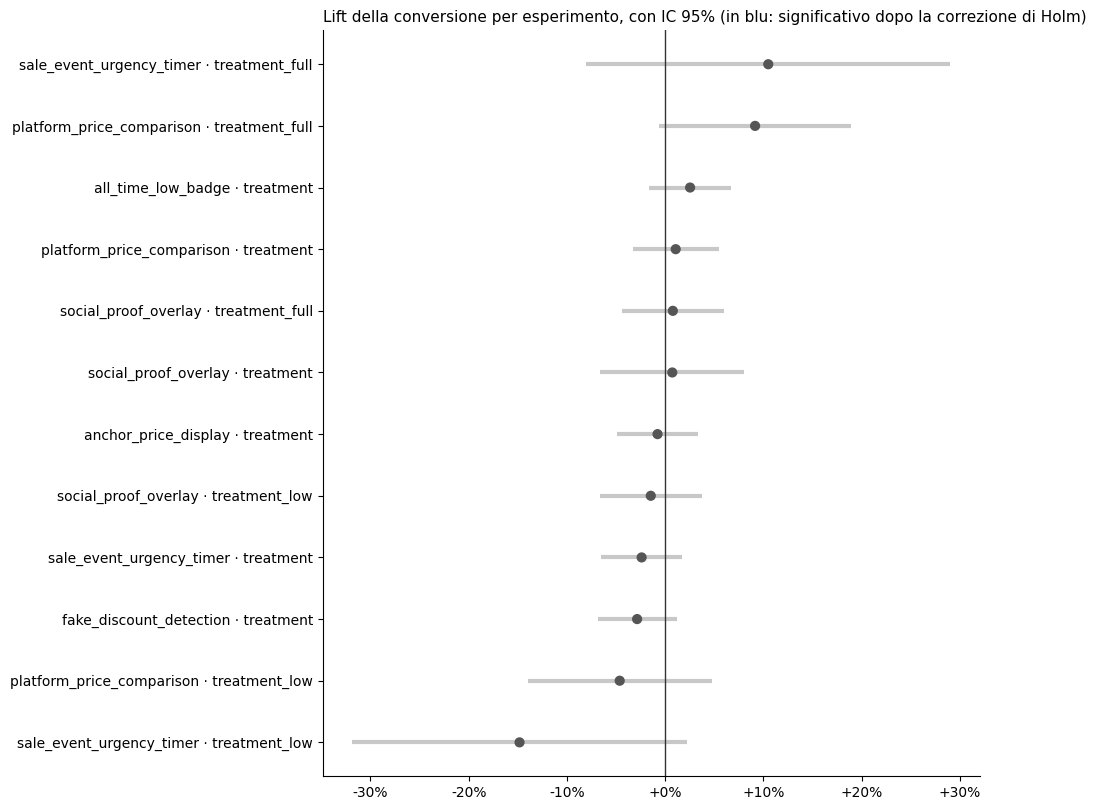

In [21]:
ordine = conf.sort_values("lift").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 0.55 * len(ordine) + 1.6))
y = np.arange(len(ordine))
ax.errorbar(ordine["lift"] * 100, y,
            xerr=[(ordine["lift"] - ordine["lift_basso"]) * 100, (ordine["lift_alto"] - ordine["lift"]) * 100],
            fmt="none", ecolor=GRIGIO, elinewidth=3)
ax.scatter(ordine["lift"] * 100, y, zorder=3, s=40,
           color=[ACCENTO if p < 0.05 else SCURO for p in ordine["p_holm"]])
ax.axvline(0, color="#333333", lw=1)
ax.set_yticks(y, [f"{e} · {v}" for e, v in zip(ordine["esperimento"], ordine["variante"])])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0f}%")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Lift della conversione per esperimento, con IC 95% (in blu: significativo dopo la correzione di Holm)",
             loc="left", fontsize=11)
plt.tight_layout()
plt.show()

### Per chi funziona: effetti per segmento

Un effetto medio può nascondere segmenti che reagiscono in modo opposto. Per ogni esperimento si stima il lift per segmento e si verifica con il **test Q di Cochran** se le differenze tra segmenti sono più grandi di quanto ci si aspetterebbe dal caso. Un p basso indica un effetto eterogeneo: la decisione può cambiare da segmento a segmento. Anche qui i test sono molti, quindi i p-value sono corretti con Holm.

Si segmenta solo per caratteristiche fissate **prima** del test. Una variabile calcolata sugli acquisti, come un segmento di valore del cliente, dipende dal risultato del test stesso e lo falserebbe. La cella seguente lo verifica: se un livello ha conversione 0% o 100%, la variabile è costruita sugli acquisti e si esclude.

In [22]:
CANDIDATE = {"segmento_cliente": "Segmento cliente", "archetipo": "Archetipo",
             "dispositivo": "Dispositivo", "canale": "Canale", "paese": "Paese"}
SEGMENTI = {}
for col, etichetta in CANDIDATE.items():
    d = q(f"""
    SELECT {col} AS livello, COUNT(*) AS unita, AVG(conversione) AS conversione
    FROM unita_test GROUP BY 1 ORDER BY 3
    """)
    costruita_sugli_acquisti = (d["conversione"].min() == 0) or (d["conversione"].max() == 1)
    if not costruita_sugli_acquisti:
        SEGMENTI[col] = etichetta
    print(f"\n{etichetta}: " + ("ESCLUSA, dipende dagli acquisti" if costruita_sugli_acquisti else "usabile"))
    print("  " + " · ".join(f"{l} {pct(c)}" for l, c in zip(d["livello"], d["conversione"])))


Segmento cliente: ESCLUSA, dipende dagli acquisti
  loyal 0,0% · at_risk 6,2% · churned 6,5% · dormant 6,9% · high_value 100,0%

Archetipo: usabile
  casual_browser 2,1% · researcher 3,1% · price_sensitive 5,5% · deal_hunter 7,2% · loyal_returner 12,9% · premium_buyer 18,5% · impulse_buyer 22,3%

Dispositivo: usabile
  tablet 8,3% · desktop 8,3% · mobile 8,4% · smart_tv 8,7%

Canale: usabile
  referral 8,1% · paid_search 8,3% · social 8,3% · direct 8,4% · organic_search 8,4% · email 8,6% · affiliate 8,6%

Paese: usabile
  UK 8,2% · SG 8,2% · AU 8,3% · US 8,3% · DE 8,4% · IN 8,5% · CA 8,5% · FR 8,6% · JP 8,6% · MX 8,9% · BR 9,0%


In [23]:
def per_segmento(esperimento, dim):
    d = q(f"""
    SELECT {dim} AS segmento, variante, COUNT(*) AS n, SUM(conversione) AS conversioni
    FROM unita_test WHERE esperimento = '{esperimento}'
    GROUP BY 1, 2
    """)
    base = controllo_di(d["variante"].unique())
    righe = []
    for segmento, g in d.groupby("segmento"):
        g = g.set_index("variante")
        if base not in g.index:
            continue
        c = g.loc[base]
        for variante in g.index.drop(base):
            t = g.loc[variante]
            pc, pt = c["conversioni"] / c["n"], t["conversioni"] / t["n"]
            se = np.sqrt(pc * (1 - pc) / c["n"] + pt * (1 - pt) / t["n"])
            # log odds ratio, con 0,5 aggiunto alle celle per evitare divisioni per zero
            a1, b1 = t["conversioni"] + 0.5, t["n"] - t["conversioni"] + 0.5
            a0, b0 = c["conversioni"] + 0.5, c["n"] - c["conversioni"] + 0.5
            righe.append({"segmento": segmento, "variante": variante, "n": c["n"] + t["n"],
                          "tasso_controllo": pc, "tasso_variante": pt,
                          "lift": (pt - pc) / pc if pc > 0 else np.nan,
                          "lift_basso": (pt - pc - Z * se) / pc if pc > 0 else np.nan,
                          "lift_alto": (pt - pc + Z * se) / pc if pc > 0 else np.nan,
                          "log_or": np.log(a1 * b0 / (b1 * a0)),
                          "var_log_or": 1 / a1 + 1 / b1 + 1 / a0 + 1 / b0})
    return pd.DataFrame(righe)


def cochran_q(seg):
    w = 1 / seg["var_log_or"]
    media = (w * seg["log_or"]).sum() / w.sum()
    q_stat = (w * (seg["log_or"] - media) ** 2).sum()
    return q_stat, stats.chi2.sf(q_stat, len(seg) - 1)


eterogeneita, dettagli = [], {}
for r in conf.itertuples(index=False):
    for dim, etichetta in SEGMENTI.items():
        seg = per_segmento(r.esperimento, dim)
        seg = seg[seg["variante"] == r.variante].reset_index(drop=True)
        if len(seg) < 2:
            continue
        dettagli[(r.esperimento, r.variante, dim)] = seg
        q_stat, p = cochran_q(seg)
        alto, basso = seg.loc[seg["lift"].idxmax()], seg.loc[seg["lift"].idxmin()]
        eterogeneita.append({"esperimento": r.esperimento, "variante": r.variante, "dimensione": etichetta,
                             "Q": round(q_stat, 1), "p": p,
                             "lift più alto": f"{alto['segmento']} {pct(alto['lift'])}",
                             "lift più basso": f"{basso['segmento']} {pct(basso['lift'])}"})
eterogeneita = pd.DataFrame(eterogeneita)
eterogeneita["p_holm"] = holm(eterogeneita["p"])
print(f"{len(eterogeneita)} test di eterogeneità; con p < 0,05 se ne aspettano circa {len(eterogeneita) * 0.05:.0f} per caso")
display(eterogeneita.assign(p=eterogeneita["p"].map(lambda x: f"{x:.2g}"),
                            p_holm=eterogeneita["p_holm"].map(lambda x: f"{x:.2g}")))

48 test di eterogeneità; con p < 0,05 se ne aspettano circa 2 per caso


,esperimento,variante,dimensione,Q,p,lift più alto,lift più basso,p_holm
0,all_time_low_badge,treatment,Archetipo,9.0,0.18,"price_sensitive 21,8%","casual_browser -7,7%",1
1,all_time_low_badge,treatment,Dispositivo,4.6,0.2,"smart_tv 20,3%","mobile -1,3%",1
2,all_time_low_badge,treatment,Canale,1.8,0.93,"paid_search 8,4%","email -1,6%",1
3,all_time_low_badge,treatment,Paese,14.5,0.15,"SG 35,7%","CA -13,7%",1
4,anchor_price_display,treatment,Archetipo,9.9,0.13,"premium_buyer 12,8%","casual_browser -12,7%",1
5,anchor_price_display,treatment,Dispositivo,0.9,0.82,"mobile 1,1%","tablet -4,8%",1
6,anchor_price_display,treatment,Canale,1.4,0.96,"direct 1,8%","affiliate -7,8%",1
7,anchor_price_display,treatment,Paese,11.5,0.32,"JP 13,1%","MX -16,9%",1
8,fake_discount_detection,treatment,Archetipo,3.3,0.77,"casual_browser 4,1%","price_sensitive -6,6%",1
9,fake_discount_detection,treatment,Dispositivo,0.5,0.91,"mobile -1,4%","tablet -5,0%",1


platform_price_comparison · treatment_full: lift medio 9,2%, per paese


,Paese,unità,conv. controllo,conv. variante,lift,IC 95%
0,MX,999,"8,11%","6,90%","-15,0%","-84,2% – 54,2%"
1,JP,1.042,"8,65%","7,55%","-12,8%","-74,5% – 48,9%"
2,FR,2.659,"8,90%","7,91%","-11,1%","-49,0% – 26,8%"
3,BR,1.568,"8,38%","8,12%","-3,1%","-56,4% – 50,3%"
4,AU,3.740,"8,46%","8,31%","-1,8%","-37,8% – 34,1%"
5,US,18.507,"8,31%","8,44%","1,6%","-14,6% – 17,7%"
6,IN,9.483,"8,51%","9,55%","12,2%","-10,8% – 35,2%"
7,UK,6.276,"8,27%","9,32%","12,6%","-15,9% – 41,1%"
8,SG,1.077,"7,83%","9,24%","18,1%","-51,9% – 88,0%"
9,CA,3.157,"7,93%","9,83%","23,9%","-17,6% – 65,4%"


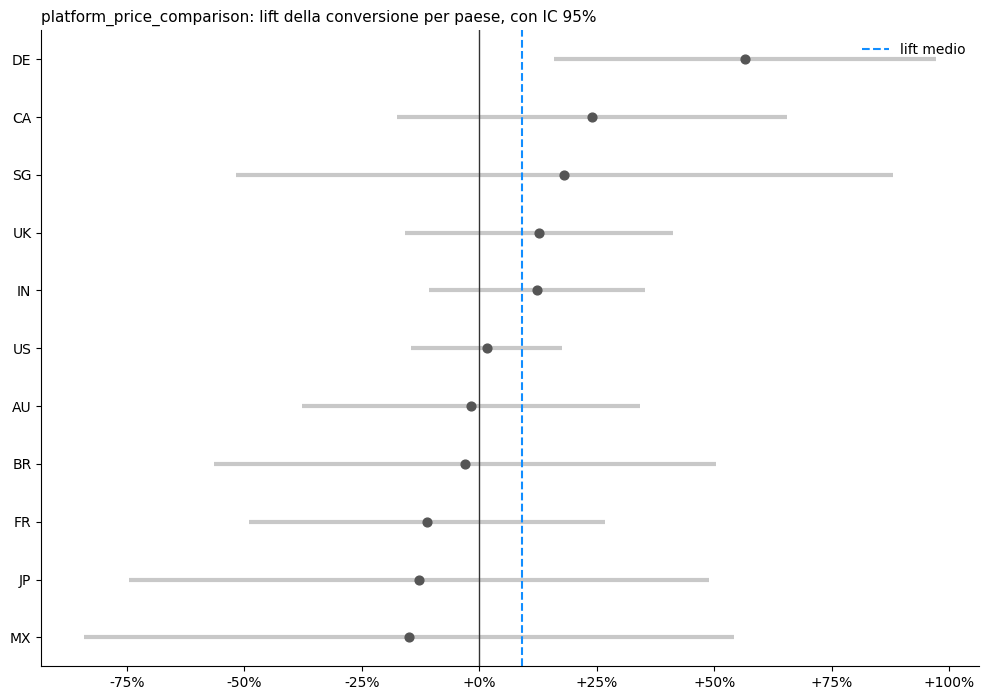

In [24]:
# Dettaglio per l'esperimento con l'effetto più netto, sulla dimensione più eterogenea
principale = conf.sort_values("p").iloc[0]
ESP, VAR = principale["esperimento"], principale["variante"]
righe_esp = eterogeneita[(eterogeneita["esperimento"] == ESP) & (eterogeneita["variante"] == VAR)]
dim_label = righe_esp.sort_values("p").iloc[0]["dimensione"]
DIM = {v: k for k, v in SEGMENTI.items()}[dim_label]
seg = dettagli[(ESP, VAR, DIM)].sort_values("lift").reset_index(drop=True)

print(f"{ESP} · {VAR}: lift medio {pct(principale['lift'])}, per {dim_label.lower()}")
display(pd.DataFrame({
    dim_label: seg["segmento"], "unità": seg["n"].map(num),
    "conv. controllo": seg["tasso_controllo"].map(lambda x: pct(x, 2)),
    "conv. variante": seg["tasso_variante"].map(lambda x: pct(x, 2)),
    "lift": seg["lift"].map(pct),
    "IC 95%": [f"{pct(b)} – {pct(a)}" for b, a in zip(seg["lift_basso"], seg["lift_alto"])],
}))

fig, ax = plt.subplots(figsize=(10, 0.5 * len(seg) + 1.6))
y = np.arange(len(seg))
ax.errorbar(seg["lift"] * 100, y,
            xerr=[(seg["lift"] - seg["lift_basso"]) * 100, (seg["lift_alto"] - seg["lift"]) * 100],
            fmt="none", ecolor=GRIGIO, elinewidth=3)
ax.scatter(seg["lift"] * 100, y, color=SCURO, zorder=3, s=40)
ax.axvline(principale["lift"] * 100, color=ACCENTO, lw=1.5, ls="--", label="lift medio")
ax.axvline(0, color="#333333", lw=1)
ax.set_yticks(y, seg["segmento"])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0f}%")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"{ESP}: lift della conversione per {dim_label.lower()}, con IC 95%", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

### Stabilità nel tempo

Un effetto che cala trimestre dopo trimestre può essere un *effetto novità*: gli utenti reagiscono alla variante perché è nuova, non perché è migliore. Si controlla sull'esperimento principale: per ogni trimestre, la conversione degli utenti attivi in quel trimestre. Il trimestre di ingresso non servirebbe, perché quasi tutti entrano nel primo.

In [25]:
tempo = q(f"""
WITH attivi AS (
  SELECT date_trunc('quarter', session_start)::DATE AS trimestre, user_id, variante,
         MAX(had_purchase::INTEGER) AS conversione
  FROM assegnazioni WHERE esperimento = '{ESP}'
  GROUP BY 1, 2, 3
)
SELECT trimestre, variante, COUNT(*) AS n, SUM(conversione) AS conversioni
FROM attivi GROUP BY 1, 2 ORDER BY 1, 2
""")
righe = []
for trimestre, g in tempo.groupby("trimestre"):
    g = g.set_index("variante")
    if principale["controllo"] not in g.index or VAR not in g.index:
        continue
    c, t = g.loc[principale["controllo"]], g.loc[VAR]
    if min(c["n"], t["n"]) < 500:
        continue
    pc, pt = c["conversioni"] / c["n"], t["conversioni"] / t["n"]
    se = np.sqrt(pc * (1 - pc) / c["n"] + pt * (1 - pt) / t["n"])
    righe.append({"trimestre": pd.Timestamp(trimestre).to_period("Q").strftime("%Y-T%q"),
                  "unità": num(c["n"] + t["n"]),
                  "lift": pct((pt - pc) / pc),
                  "IC 95%": f"{pct((pt - pc - Z * se) / pc)} – {pct((pt - pc + Z * se) / pc)}"})
print(f"{ESP} · {VAR}: lift per trimestre, utenti attivi nel trimestre (esclusi i trimestri con meno di 500 utenti per gruppo)")
display(pd.DataFrame(righe))

platform_price_comparison · treatment_full: lift per trimestre, utenti attivi nel trimestre (esclusi i trimestri con meno di 500 utenti per gruppo)


,trimestre,unità,lift,IC 95%
0,2023-T1,39.179,"8,9%","-20,1% – 37,8%"
1,2023-T2,39.433,"-5,6%","-33,7% – 22,5%"
2,2023-T3,39.200,"-8,0%","-33,6% – 17,5%"
3,2023-T4,41.949,"10,5%","-14,0% – 35,1%"
4,2024-T1,39.141,"6,1%","-23,4% – 35,7%"
5,2024-T2,39.511,"-17,5%","-42,8% – 7,7%"
6,2024-T3,39.254,"19,0%","-11,5% – 49,5%"
7,2024-T4,41.658,"40,3%","12,9% – 67,7%"


## 6 · Dagli esperimenti alle decisioni

La sezione 5 dice che nessun effetto è certo. Qui si fa il passo successivo, quello che serve a chi deve decidere:

1. **intervalli più stretti con gli stessi utenti**, correggendo per l'archetipo del cliente, e metriche più sensibili della conversione;
2. **gli esperimenti letti insieme**: le versioni complete contro quelle leggere, e quanto valgono di solito le modifiche provate;
3. **una regola di decisione** che tiene conto del rischio, non solo della significatività;
4. **un piano per i prossimi test**, dimensionato su effetti realistici.

### Intervalli più stretti con gli stessi utenti

L'archetipo del cliente cambia moltissimo la probabilità di acquisto (dal 2% al 22% circa). Confrontare variante e controllo dentro ogni archetipo, e poi fare la media pesata (*post-stratificazione*, la stessa idea di CUPED), riduce il peso di questa variabilità nel confronto. L'archetipo è fissato prima del test, quindi la correzione non introduce distorsioni.

Insieme alla conversione si guardano due metriche anticipate, più frequenti e quindi più sensibili: l'aggiunta al carrello e l'inizio del checkout. I p-value sono corretti con Holm dentro ogni metrica.

In [26]:
strati = q("""
SELECT esperimento, variante, archetipo, COUNT(*) AS n,
       SUM(conversione) AS conversione, SUM(carrello) AS carrello, SUM(checkout) AS checkout
FROM unita_test GROUP BY 1, 2, 3
""")


def confronto_corretto(esperimento, variante, base, metrica="conversione"):
    d = strati[strati["esperimento"] == esperimento]
    t = d[d["variante"] == variante].set_index("archetipo")
    c = d[d["variante"] == base].set_index("archetipo")
    comuni = t.index.intersection(c.index)
    t, c = t.loc[comuni, ["n", metrica]].astype(float), c.loc[comuni, ["n", metrica]].astype(float)
    pt, pc = t[metrica] / t["n"], c[metrica] / c["n"]
    peso = (t["n"] + c["n"]) / (t["n"] + c["n"]).sum()
    PT, PC = t[metrica].sum() / t["n"].sum(), c[metrica].sum() / c["n"].sum()
    return {
        "pc": PC, "pt": PT,
        "diff_grezza": PT - PC,
        "se_grezzo": np.sqrt(PT * (1 - PT) / t["n"].sum() + PC * (1 - PC) / c["n"].sum()),
        "diff": (peso * (pt - pc)).sum(),
        "se": np.sqrt((peso ** 2 * (pt * (1 - pt) / t["n"] + pc * (1 - pc) / c["n"])).sum()),
    }


righe = []
for r in conf.itertuples(index=False):
    for metrica in ["conversione", "carrello", "checkout"]:
        righe.append({"esperimento": r.esperimento, "variante": r.variante, "metrica": metrica,
                      **confronto_corretto(r.esperimento, r.variante, r.controllo, metrica)})
corr = pd.DataFrame(righe)
corr["lift"] = corr["diff"] / corr["pc"]
corr["lift_basso"] = (corr["diff"] - Z * corr["se"]) / corr["pc"]
corr["lift_alto"] = (corr["diff"] + Z * corr["se"]) / corr["pc"]
corr["p"] = 2 * stats.norm.sf(np.abs(corr["diff"] / corr["se"]))
corr["p_holm"] = corr.groupby("metrica")["p"].transform(holm)
corr["ampiezza"] = corr["se"] / corr["se_grezzo"] - 1

c1 = corr[corr["metrica"] == "conversione"].reset_index(drop=True)
print("Conversione: prima e dopo la correzione per l'archetipo")
display(pd.DataFrame({
    "esperimento": c1["esperimento"], "variante": c1["variante"],
    "lift grezzo": (c1["diff_grezza"] / c1["pc"]).map(pct),
    "lift corretto": c1["lift"].map(pct),
    "IC 95% corretto": [f"{pct(b)} – {pct(a)}" for b, a in zip(c1["lift_basso"], c1["lift_alto"])],
    "ampiezza dell'intervallo rispetto a prima": c1["ampiezza"].map(lambda x: ("+" if x > 0 else "") + pct(x)),
    "p Holm": c1["p_holm"].map(lambda x: f"{x:.2g}"),
}))

anticipate = corr[corr["metrica"] != "conversione"].pivot_table(
    index=["esperimento", "variante"], columns="metrica", values=["lift", "p_holm"], aggfunc="first")
print("\nMetriche anticipate, corrette per l'archetipo (lift e p corretto con Holm)")
display(pd.DataFrame({
    "lift carrello": anticipate[("lift", "carrello")].map(pct),
    "p Holm carrello": anticipate[("p_holm", "carrello")].map(lambda x: f"{x:.2g}"),
    "lift checkout": anticipate[("lift", "checkout")].map(pct),
    "p Holm checkout": anticipate[("p_holm", "checkout")].map(lambda x: f"{x:.2g}"),
}))

Conversione: prima e dopo la correzione per l'archetipo


,esperimento,variante,lift grezzo,lift corretto,IC 95% corretto,ampiezza dell'intervallo rispetto a prima,p Holm
0,all_time_low_badge,treatment,"2,5%","2,5%","-1,6% – 6,5%","-2,9%",1
1,anchor_price_display,treatment,"-0,8%","-0,9%","-4,9% – 3,1%","-3,2%",1
2,fake_discount_detection,treatment,"-2,9%","-2,0%","-5,9% – 1,9%","-3,1%",1
3,platform_price_comparison,treatment,"1,1%","1,7%","-2,6% – 5,9%","-3,0%",1
4,platform_price_comparison,treatment_full,"9,2%","9,2%","-0,2% – 18,6%","-3,6%",0.67
5,platform_price_comparison,treatment_low,"-4,6%","-4,0%","-13,1% – 5,1%","-2,6%",1
6,sale_event_urgency_timer,treatment,"-2,4%","-1,6%","-5,6% – 2,4%","-3,1%",1
7,sale_event_urgency_timer,treatment_full,"10,5%","11,5%","-6,2% – 29,2%","-4,3%",1
8,sale_event_urgency_timer,treatment_low,"-14,8%","-14,1%","-30,7% – 2,5%","-2,5%",1
9,social_proof_overlay,treatment,"0,7%","1,1%","-6,0% – 8,2%","-3,0%",1



Metriche anticipate, corrette per l'archetipo (lift e p corretto con Holm)


lift carrello p Holm carrello lift checkout p Holm checkout
esperimento               variante                                                                  
all_time_low_badge        treatment               1,4%               1          2,0%               1
anchor_price_display      treatment               0,6%               1         -0,7%               1
fake_discount_detection   treatment              -0,0%               1         -0,3%               1
platform_price_comparison treatment              -0,4%               1          0,8%               1
                          treatment_full         -0,4%               1          6,3%               1
                          treatment_low          -4,8%            0.33         -3,3%               1
sale_event_urgency_timer  treatment              -0,2%               1         -1,0%               1
                          treatment_full          6,0%               1         12,9%               1
                          treatment_low          -2,5%               1        -12,3%               1
social_proof_overlay      treatment              -0,8%               1         -1,1%               1
                          treatment_full         -1,5%               1         -0,4%               1
                          treatment_low          -0,6%               1         -0,6%               1

### Versione completa contro versione leggera

Tre esperimenti hanno una versione completa e una leggera della stessa idea. Il confronto diretto tra le due dice se l'intensità conta. È un confronto scelto dopo aver visto i dati, quindi va letto come un'ipotesi da verificare, non come una prova. La stima combinata pesa ogni esperimento per la sua precisione.

In [27]:
righe = []
for esperimento in conf["esperimento"].unique():
    varianti = set(strati.loc[strati["esperimento"] == esperimento, "variante"])
    if {"treatment_full", "treatment_low"} <= varianti:
        righe.append({"esperimento": esperimento,
                      **confronto_corretto(esperimento, "treatment_full", "treatment_low")})
cl = pd.DataFrame(righe)
if len(cl):
    cl["p"] = 2 * stats.norm.sf(np.abs(cl["diff"] / cl["se"]))
    display(pd.DataFrame({
        "esperimento": cl["esperimento"],
        "conversione leggera": cl["pc"].map(lambda x: pct(x, 2)),
        "conversione completa": cl["pt"].map(lambda x: pct(x, 2)),
        "differenza corretta (punti)": (cl["diff"] * 100).map(lambda x: num(x, 2)),
        "IC 95% (punti)": [f"{num((d - Z * s) * 100, 2)} – {num((d + Z * s) * 100, 2)}" for d, s in zip(cl["diff"], cl["se"])],
        "p": cl["p"].map(lambda x: f"{x:.2g}"),
    }))
    peso = 1 / cl["se"] ** 2
    comb, se_comb = (peso * cl["diff"]).sum() / peso.sum(), np.sqrt(1 / peso.sum())
    p_comb = 2 * stats.norm.sf(abs(comb / se_comb))
    print(f"\nStima combinata: la versione completa converte {num(comb * 100, 2)} punti in più della leggera "
          f"(IC 95% da {num((comb - Z * se_comb) * 100, 2)} a {num((comb + Z * se_comb) * 100, 2)}), p = {p_comb:.2g}. "
          f"Le versioni complete battono le leggere in {(cl['diff'] > 0).sum()} esperimenti su {len(cl)}.")

,esperimento,conversione leggera,conversione completa,differenza corretta (punti),IC 95% (punti),p
0,platform_price_comparison,"7,92%","9,06%","1,09","0,06 – 2,12",0.038
1,sale_event_urgency_timer,"7,28%","9,45%","2,18","0,15 – 4,22",0.035
2,social_proof_overlay,"8,25%","8,44%","0,19","-0,27 – 0,65",0.42



Stima combinata: la versione completa converte 0,41 punti in più della leggera (IC 95% da 0,00 a 0,82), p = 0.048. Le versioni complete battono le leggere in 3 esperimenti su 3.


### Quanto valgono di solito le modifiche provate

Una meta-analisi a effetti casuali (DerSimonian-Laird) stima l'effetto medio delle 12 varianti e quanto gli effetti veri cambiano da una variante all'altra. Serve a due cose:

- **ridimensionare i risultati estremi**: con molti confronti, il migliore tende a sovrastimare il proprio effetto (la "maledizione del vincitore"). L'effetto ridimensionato è una stima più prudente per decidere e per dimensionare i test di conferma;
- **sapere quale effetto aspettarsi** dalle prossime idee, e quindi quanti utenti servono.

Le varianti di uno stesso esperimento condividono il controllo, quindi la stima è approssimata.

In [28]:
y = conf["lift"].to_numpy()
v = (((conf["diff_alto"] - conf["diff_basso"]) / (2 * Z)) / conf["tasso_controllo"]).to_numpy() ** 2
w = 1 / v
mu_fisso = (w * y).sum() / w.sum()
Q = (w * (y - mu_fisso) ** 2).sum()
k = len(y)
tau2 = max(0.0, (Q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
w_rand = 1 / (v + tau2)
mu = (w_rand * y).sum() / w_rand.sum()
se_mu = np.sqrt(1 / w_rand.sum())
conf["lift_ridimensionato"] = mu + tau2 / (tau2 + v) * (y - mu)

print(f"Effetto medio delle varianti: {pct(mu)} (IC 95% da {pct(mu - Z * se_mu)} a {pct(mu + Z * se_mu)})")
print(f"Variabilità degli effetti veri tra varianti (tau): {pct(np.sqrt(tau2))}; "
      f"test di eterogeneità Q = {num(Q, 1)}, p = {stats.chi2.sf(Q, k - 1):.2g}\n")
display(pd.DataFrame({
    "esperimento": conf["esperimento"], "variante": conf["variante"],
    "lift osservato": conf["lift"].map(pct),
    "lift ridimensionato": conf["lift_ridimensionato"].map(pct),
}).sort_values("lift osservato", key=lambda s: s.str.replace(",", ".").str.rstrip("%").astype(float), ascending=False))

Effetto medio delle varianti: -0,3% (IC 95% da -2,1% a 1,5%)
Variabilità degli effetti veri tra varianti (tau): 1,4%; test di eterogeneità Q = 13,7, p = 0.25



,esperimento,variante,lift osservato,lift ridimensionato
7,sale_event_urgency_timer,treatment_full,"10,5%","-0,1%"
4,platform_price_comparison,treatment_full,"9,2%","0,4%"
0,all_time_low_badge,treatment,"2,5%","0,6%"
3,platform_price_comparison,treatment,"1,1%","0,1%"
10,social_proof_overlay,treatment_full,"0,8%","-0,1%"
9,social_proof_overlay,treatment,"0,7%","-0,2%"
1,anchor_price_display,treatment,"-0,8%","-0,5%"
11,social_proof_overlay,treatment_low,"-1,5%","-0,6%"
6,sale_event_urgency_timer,treatment,"-2,4%","-1,0%"
2,fake_discount_detection,treatment,"-2,9%","-1,1%"


### Una regola di decisione che tiene conto del rischio

Aspettare la significatività ha un costo: una modifica che probabilmente funziona resta ferma. Per modifiche economiche e reversibili si può decidere con la lettura bayesiana, fissando le soglie prima:

- **lancio graduale** se la probabilità che la variante sia migliore è almeno il 90% e la perdita attesa, se invece è peggiore, non supera lo 0,1% della conversione. Si lancia a una parte degli utenti e si torna indietro se la probabilità scende sotto l'80%;
- **scartare** se la probabilità è al massimo il 10%;
- **non prioritario** negli altri casi: i dati non indicano una direzione.

In [29]:
rng = np.random.default_rng(7)
righe = []
for r in conf.itertuples(index=False):
    a = rng.beta(1 + r.conv_controllo, 1 + r.n_controllo - r.conv_controllo, ESTRAZIONI)
    b = rng.beta(1 + r.conv_variante, 1 + r.n_variante - r.conv_variante, ESTRAZIONI)
    p_meglio = (b > a).mean()
    perdita = np.maximum(a - b, 0).mean() / r.tasso_controllo
    rischio = (b / a - 1 < -0.02).mean()
    if p_meglio >= 0.90 and perdita <= 0.001:
        scelta = "Lancio graduale"
    elif p_meglio <= 0.10:
        scelta = "Scartare"
    else:
        scelta = "Non prioritario"
    righe.append({"esperimento": r.esperimento, "variante": r.variante,
                  "P(migliore)": pct(p_meglio), "perdita attesa": pct(perdita, 2),
                  "P(peggiora più del 2%)": pct(rischio), "decisione": scelta})
decisioni = pd.DataFrame(righe)
display(decisioni)

,esperimento,variante,P(migliore),perdita attesa,P(peggiora più del 2%),decisione
0,all_time_low_badge,treatment,"88,4%","0,12%","1,6%",Non prioritario
1,anchor_price_display,treatment,"35,6%","1,28%","27,7%",Non prioritario
2,fake_discount_detection,treatment,"8,2%","2,93%","66,3%",Scartare
3,platform_price_comparison,treatment,"68,4%","0,46%","8,4%",Non prioritario
4,platform_price_comparison,treatment_full,"97,2%","0,05%","1,0%",Lancio graduale
5,platform_price_comparison,treatment_low,"17,5%","4,93%","70,0%",Non prioritario
6,sale_event_urgency_timer,treatment,"12,5%","2,53%","57,7%",Non prioritario
7,sale_event_urgency_timer,treatment_full,"88,3%","0,50%","7,8%",Non prioritario
8,sale_event_urgency_timer,treatment_low,"5,7%","14,32%","91,4%",Scartare
9,social_proof_overlay,treatment,"58,1%","1,13%","22,8%",Non prioritario


### Piano per i prossimi test

Quanti utenti per gruppo servono per vedere un certo miglioramento della conversione, con potenza dell'80% e confidenza del 95%, e quale parte della base utenti occuperebbe il test. Poi la dimensione dei test di conferma per le due varianti più promettenti, calcolata sia sull'effetto osservato sia su quello ridimensionato.

In [30]:
p0 = conf["tasso_controllo"].mean()
utenti_totali = float(controllo["utenti"].iloc[0])
piano = pd.DataFrame({"miglioramento da vedere": [0.02, 0.03, 0.05, 0.10]})
piano["utenti per gruppo"] = [unita_necessarie(p0, p0 * (1 + l)) for l in piano["miglioramento da vedere"]]
piano["quota della base utenti"] = 2 * piano["utenti per gruppo"] / utenti_totali
print(f"Conversione di partenza: {pct(p0, 2)} · base utenti: {num(utenti_totali)}")
display(pd.DataFrame({
    "miglioramento da vedere": piano["miglioramento da vedere"].map(lambda x: "+" + pct(x, 0)),
    "utenti per gruppo": piano["utenti per gruppo"].map(num),
    "quota della base utenti (2 gruppi)": piano["quota della base utenti"].map(lambda x: pct(x, 0)),
}))

promettenti = conf[conf["variante"] == "treatment_full"].sort_values("lift", ascending=False).head(2)
righe = []
for r in promettenti.itertuples(index=False):
    righe.append({"esperimento": r.esperimento, "variante": r.variante,
                  "lift osservato": pct(r.lift),
                  "utenti per gruppo, sull'osservato": num(unita_necessarie(r.tasso_controllo, r.tasso_controllo * (1 + r.lift))),
                  "lift ridimensionato": pct(r.lift_ridimensionato),
                  "utenti per gruppo, sul ridimensionato": num(unita_necessarie(r.tasso_controllo, r.tasso_controllo * (1 + max(r.lift_ridimensionato, 0.005))))})
print("\nTest di conferma")
display(pd.DataFrame(righe))

Conversione di partenza: 8,41% · base utenti: 498.996


,miglioramento da vedere,utenti per gruppo,quota della base utenti (2 gruppi)
0,+2%,431.206,173%
1,+3%,192.505,77%
2,+5%,69.918,28%
3,+10%,17.862,7%



Test di conferma


,esperimento,variante,lift osservato,"utenti per gruppo, sull'osservato",lift ridimensionato,"utenti per gruppo, sul ridimensionato"
0,sale_event_urgency_timer,treatment_full,"10,5%",15.973,"-0,1%",6.729.293
1,platform_price_comparison,treatment_full,"9,2%",21.562,"0,4%",6.950.990


## 7 · Lettura dei risultati

Esecuzione dell'8 novembre 2026 su 5.651.586 sessioni del 2023–2024, esclusi i bot. È un progetto di studio su dati simulati: i numeri servono a mostrare il metodo.

**Funnel (domanda 2).** Su 100 sessioni, 3,2 aggiungono un prodotto al carrello, 1,1 avviano il checkout e 0,8 comprano. Canale, browser e dispositivo non cambiano nulla (V di Cramér sotto 0,01). L'unica differenza rilevante è **Flipkart**: arriva al checkout il 15,9% dei carrelli, contro il 37,9% delle altre piattaforme (V 0,17). Il calo è uguale su ogni dispositivo, canale, paese e trimestre, quindi dipende dal checkout di Flipkart e non da un gruppo di clienti. Con il tasso delle altre piattaforme, Flipkart avrebbe fatto 4.634 acquisti in più in due anni: circa $425.000 di ricavi l'anno.

**Attribution (domanda 1).** Non c'è un segnale da attribuire. Ogni utente arriva sempre dallo stesso canale e tutti i canali convertono tra lo 0,78% e lo 0,84%. Per questo i cinque modelli, Markov compreso, coincidono con la quota di traffico, con scarti sotto 0,2 punti. Il valore dei canali va misurato in un altro modo: il notebook 04 confronta il valore dei clienti per canale e progetta un test geografico.

**A/B test (domanda 5): cosa dicono i dati.**

- **Il disegno è corretto.** Ogni utente resta nella stessa variante, i gruppi sono bilanciati (V di Cramér al massimo 0,014) e i tre esperimenti a due varianti sono divisi a metà.
- **Nessuna variante ha un effetto certo** dopo la correzione di Holm, né sulla conversione né sui ricavi per utente.
- **I test erano piccoli.** Con circa 50.000 utenti per gruppo potevano vedere solo effetti dal 6% in su; le versioni complete e leggere, con 1.300–5.300 utenti, solo effetti dal 13% in su.
- **Nessuna differenza tra segmenti e nessun effetto novità.** Su 48 test di eterogeneità nessuno resta significativo dopo la correzione. Il segmento cliente del dataset è escluso perché costruito sugli acquisti.

**A/B test: cosa si può decidere comunque (sezione 6).**

- **La correzione per l'archetipo aiuta poco:** gli intervalli si stringono solo del 3% circa. Anche carrello e checkout non mostrano effetti certi.
- **L'intensità conta.** In tutti e tre gli esperimenti con due versioni, la completa converte più della leggera: +1,1 punti nel confronto prezzi (p 0,04), +2,2 nel timer dei saldi (p 0,04), +0,2 nella riprova sociale. Insieme fanno +0,4 punti (IC da 0,0 a 0,8; p 0,048). È un confronto scelto dopo aver visto i dati, quindi è un'ipotesi da verificare, ma indica che le versioni leggere non servono.
- **Le modifiche provate valgono poco.** La meta-analisi delle 12 varianti stima un effetto medio vicino a zero (−0,3%, IC da −2,1% a +1,5%), con differenze reali tra varianti di circa 1,4 punti. Ridimensionato, il +9,2% del confronto prezzi completo diventa +0,4%: il risultato migliore di tanti confronti tende a sovrastimare il proprio effetto.
- **Il confronto prezzi completo si può lanciare in modo graduale.** Ha il 97% di probabilità di migliorare la conversione e una perdita attesa dello 0,05%: il rischio è minimo. Il guadagno da aspettarsi però è piccolo, più vicino a +0,4% che a +9%. Due varianti vanno scartate: l'avviso sugli sconti gonfiati e la versione leggera del timer.
- **Con questa base utenti si possono testare solo idee grandi.** Per vedere un +5% servono 70.000 utenti per gruppo (28% della base); per un +3%, 192.500 (77%); per un +2% non bastano tutti gli utenti.

**Raccomandazioni**

1. **Flipkart:** ricostruire il passaggio dal carrello al checkout (pagine, dati richiesti, metodi di pagamento) e testare una correzione. Vale circa $425.000 l'anno.
2. **Confronto prezzi completo:** lanciarlo in modo graduale, con una soglia per tornare indietro fissata prima, e aspettarsi un guadagno piccolo.
3. **Prossimi esperimenti:** provare solo modifiche capaci di spostare la conversione di almeno il 5%, nella versione completa, un esperimento alla volta sulla stessa pagina. Effetto minimo e numero di utenti si fissano prima dell'avvio.
4. **Canali:** misurare il valore di Paid Search con il test geografico del notebook 04.

## 8 · Dati per la dashboard Tableau Public

Un file Excel con un foglio per ogni vista della dashboard. I numeri sono già aggregati: Tableau non deve leggere i 5,7 milioni di sessioni.

- `funnel`: una riga per piattaforma e fase, con le quote sul totale e sulla fase precedente;
- `flipkart_dettaglio`: il passaggio dal carrello al checkout della piattaforma peggiore e delle altre, per dispositivo, canale, paese e trimestre;
- `canali`: conversione per canale e quota di conversioni secondo i cinque modelli di attribution;
- `esperimenti`: un riga per variante, con lift, intervallo di confidenza, p-value, probabilità bayesiana e decisione.

Il file si scarica da solo alla fine dell'esecuzione. Se il browser lo blocca, è nel pannello *File* di Colab, a sinistra, nella cartella `content`.

In [31]:
FASI = [("Sessioni", "sessioni"), ("Carrello", "carrello"), ("Checkout", "checkout"), ("Acquisto", "acquisto")]
righe = []
for _, r in funnel_dim["platform"].iterrows():
    precedente = None
    for ordine, (fase, col) in enumerate(FASI, start=1):
        n = float(r[col])
        righe.append({"piattaforma": r["valore"],
                      "gruppo": r["valore"] if r["valore"] == PEGGIORE else "Altre piattaforme",
                      "ordine_fase": ordine, "fase": fase, "sessioni": int(n),
                      "quota_sul_totale": n / float(r["sessioni"]),
                      "quota_sulla_fase_precedente": n / precedente if precedente else None})
        precedente = n
foglio_funnel = pd.DataFrame(righe)

righe = []
for espressione, etichetta in SCOMPOSIZIONI.items():
    d = q(f"""
    SELECT {espressione} AS valore,
           SUM(CASE WHEN platform = '{PEGGIORE}' THEN 1 ELSE 0 END) AS carrelli_peggiore,
           SUM(CASE WHEN platform = '{PEGGIORE}' THEN checkout_started::INTEGER ELSE 0 END) AS checkout_peggiore,
           SUM(CASE WHEN platform <> '{PEGGIORE}' THEN 1 ELSE 0 END) AS carrelli_altre,
           SUM(CASE WHEN platform <> '{PEGGIORE}' THEN checkout_started::INTEGER ELSE 0 END) AS checkout_altre
    FROM sessioni WHERE had_cart_event
    GROUP BY 1 ORDER BY 1
    """)
    for _, r in d.iterrows():
        valore = r["valore"]
        if etichetta == "Trimestre":
            valore = pd.Timestamp(valore).to_period("Q").strftime("%Y-T%q")
        for gruppo, suffisso in [(PEGGIORE, "peggiore"), ("Altre piattaforme", "altre")]:
            carrelli, checkout = float(r["carrelli_" + suffisso]), float(r["checkout_" + suffisso])
            righe.append({"dimensione": etichetta, "valore": str(valore), "gruppo": gruppo,
                          "carrelli": int(carrelli), "checkout": int(checkout),
                          "checkout_su_carrello": checkout / carrelli if carrelli else None})
foglio_dettaglio = pd.DataFrame(righe)

conv_canali = funnel_dim["traffic_source"].rename(columns={"valore": "canale"})
basso, alto = wilson(conv_canali["acquisto"], conv_canali["sessioni"])
foglio_canali = (attribution.reset_index()
                 .rename(columns={"Quota di sessioni": "quota_sessioni", "Last click": "last_click",
                                  "First click": "first_click", "Lineare": "lineare", "A U": "a_u",
                                  "Markov": "markov"})
                 .merge(pd.DataFrame({"canale": conv_canali["canale"],
                                      "acquisti": conv_canali["acquisto"].astype(int),
                                      "conversione": conv_canali["Conversione totale"],
                                      "conversione_ic_basso": basso, "conversione_ic_alto": alto}),
                        on="canale"))
foglio_canali = foglio_canali[["canale", "sessioni", "acquisti", "conversione", "conversione_ic_basso",
                               "conversione_ic_alto", "quota_sessioni", "last_click", "first_click",
                               "lineare", "a_u", "markov"]]

foglio_esperimenti = conf[["esperimento", "variante", "n_controllo", "n_variante", "tasso_controllo",
                           "tasso_variante", "lift", "lift_basso", "lift_alto", "p", "p_holm",
                           "P_migliore", "mde_rel", "n_per_osservato", "decisione"]].copy()
foglio_esperimenti.insert(0, "etichetta", foglio_esperimenti["esperimento"] + " · " + foglio_esperimenti["variante"])
foglio_esperimenti["esito"] = (foglio_esperimenti["decisione"].str.split(":").str[0]
                               .str.replace(r" \(MDE.*", "", regex=True))
foglio_esperimenti = foglio_esperimenti.rename(columns={"P_migliore": "prob_variante_migliore",
                                                        "n_per_osservato": "utenti_per_confermare"})

FILE_TABLEAU = "/content/tableau_funnel_esperimenti.xlsx"
fogli = {"funnel": foglio_funnel, "flipkart_dettaglio": foglio_dettaglio,
         "canali": foglio_canali, "esperimenti": foglio_esperimenti}
with pd.ExcelWriter(FILE_TABLEAU) as writer:
    for nome, foglio in fogli.items():
        foglio.to_excel(writer, sheet_name=nome, index=False)
for nome, foglio in fogli.items():
    print(f"{nome:20s} {len(foglio):4d} righe · {', '.join(foglio.columns)}")

try:
    from google.colab import files
    files.download(FILE_TABLEAU)
except ImportError:
    print("File salvato in", FILE_TABLEAU)

funnel                 20 righe · piattaforma, gruppo, ordine_fase, fase, sessioni, quota_sul_totale, quota_sulla_fase_precedente
flipkart_dettaglio     60 righe · dimensione, valore, gruppo, carrelli, checkout, checkout_su_carrello
canali                  7 righe · canale, sessioni, acquisti, conversione, conversione_ic_basso, conversione_ic_alto, quota_sessioni, last_click, first_click, lineare, a_u, markov
esperimenti            12 righe · etichetta, esperimento, variante, n_controllo, n_variante, tasso_controllo, tasso_variante, lift, lift_basso, lift_alto, p, p_holm, prob_variante_migliore, mde_rel, utenti_per_confermare, decisione, esito


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>